pandas 3.0.3 | numpy 2.5.1
scikit-learn 1.9.0 | xgboost 3.4.1 | shap 0.53.0

1-1. 데이터 크기와 변수명
행(환자 방문 수): 58,124  |  열(변수 수): 49
요청서에는 있으나 데이터에 없는 변수: 없음
데이터에는 있으나 요청서에 없는 변수: 없음

변수명 목록: ['visit_month', 'day_of_week', 'arrival_time', 'ems_arrival', 'vitals_during_visit', 'age', 'residence', 'sex', 'insurance', 'no_payment', 'region', 'temp', 'heart_rate', 'resp_rate', 'sys_bp', 'dias_bp', 'spo2', 'pain_score', 'seen_last_72h', 'episode', 'is_injury_poison', 'hist_alzheimers', 'hist_asthma', 'hist_cancer', 'hist_stroke', 'hist_ckd', 'hist_copd', 'hist_chf', 'hist_cad', 'hist_depression', 'hist_diabetes_t1', 'hist_diabetes_t2', 'hist_diabetes_unspec', 'hist_esrd', 'hist_pe', 'hist_hiv', 'hist_high_cholesterol', 'hist_hypertension', 'hist_obesity', 'hist_sleep_apnea', 'hist_osteoporosis', 'hist_substance_abuse', 'intervention_iv_fluids', 'target_triage_acuity', 'wait_time_minutes', 'race', 'year', 'chief_complaint_text', 'injury_cause_text']

1-2. 변수별 데이터 타입


,dtype,n_unique,example
visit_month,int64,12,12
day_of_week,int64,7,1
arrival_time,float64,1440,2046.0
ems_arrival,str,4,No
vitals_during_visit,float64,2,1.0
age,int64,95,5
residence,str,6,Private residence
sex,str,2,Male
insurance,str,9,Unknown/Blank
no_payment,int64,2,0



1-3. 결측치 확인 (원본)


,n_NaN(빈칸),"n_코드결측(-9,-8,-7)",n_총결측,총결측_%
pain_score,14805,0,14805,25.47
wait_time_minutes,6700,0,6700,11.53
dias_bp,5199,0,5199,8.94
sys_bp,5152,0,5152,8.86
seen_last_72h,2682,0,2682,4.61
spo2,2202,0,2202,3.79
temp,2045,0,2045,3.52
is_injury_poison,1857,0,1857,3.19
heart_rate,1649,0,1649,2.84
resp_rate,1582,0,1582,2.72



1-4. 중복 행 확인
완전히 같은 행: 5건 (0.009%)
※ NHAMCS에는 환자 고유번호가 없어, 값이 모두 같은 행이 우연히 존재할 수 있습니다.
  그래서 자동 삭제하지 않고 개수만 보고합니다. (삭제하려면 아래 DROP_DUPLICATES=True)

1-5. 수치형 변수 기술통계 (원본, 코드결측 포함 상태)


,count,mean,std,min,1%,25%,50%,75%,99%,max,skew
visit_month,58124.0,6.20,3.48,1.0,1.0,3.0,6.0,9.0,12.0,12.0,0.05
day_of_week,58124.0,3.94,1.96,1.0,1.0,2.0,4.0,6.0,7.0,7.0,0.06
arrival_time,57113.0,1369.10,588.13,0.0,21.0,1006.0,1414.0,1836.0,2338.0,2359.0,-0.41
vitals_during_visit,57766.0,1.43,0.50,1.0,1.0,1.0,1.0,2.0,2.0,2.0,0.28
age,58124.0,39.70,24.60,0.0,0.0,20.0,38.0,59.0,91.0,94.0,0.19
no_payment,58124.0,0.01,0.12,0.0,0.0,0.0,0.0,0.0,1.0,1.0,8.12
temp,56079.0,98.31,1.01,84.0,96.4,97.8,98.2,98.6,102.6,109.9,1.82
heart_rate,56475.0,92.97,39.22,0.0,54.0,77.0,88.0,103.0,169.0,998.0,15.42
resp_rate,56542.0,19.47,6.17,0.0,14.0,16.0,18.0,20.0,44.0,150.0,6.54
sys_bp,52972.0,134.90,24.40,0.0,89.0,118.0,132.0,149.0,206.0,289.0,0.72


... (7 outputs left out)

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
value,51424.0,33.4,62.4,0.0,1.0,5.0,14.0,35.0,131.0,274.0,1440.0



2-1. 복사본 생성 및 숫자형 변환

2-2. -9/-8/-7 코드 → 결측(NaN)
코드결측 없음

2-3. 활력징후 단위 점검 및 생리학적 불가능 값 → 결측
  temp 중앙값 98.2 → 단위 °F 로 판단, 허용범위 (85, 110)


,허용범위,불가능값→결측 개수
age,"(0, 110)",0
temp,"(85, 110)",1
heart_rate,"(20, 250)",128
resp_rate,"(4, 70)",168
sys_bp,"(40, 300)",2
dias_bp,"(10, 200)",27
spo2,"(50, 100)",153
pain_score,"(0, 10)",0



2-4. 종속변수 정리
응급도가 [1, 2, 3, 4, 5]가 아닌 값(미분류·기타) → 결측 처리: 0건
대기시간이 음수인 값 → 결측 처리: 0건
대기시간 최댓값: 1,440분 (극단값은 지우지 않고 그대로 둡니다. 뒤에서 영향 점검)

2-5. 도착시각 → 시(hour) 변환
arrival_time 해석: HHMM 형식(예: 1435 = 14시 35분)  | 예시 원본값 [2046.0, 1907.0, 1435.0, 1736.0, 1718.0] → 시 [20.0, 19.0, 14.0, 17.0, 17.0]
※ 위 해석이 데이터 설명서와 다르면 알려주세요. (잘못 해석하면 시간 관련 결과가 틀어집니다)

2-6. 범주형·텍스트 변수 정리
수치형 변수: ['age', 'temp', 'heart_rate', 'resp_rate', 'sys_bp', 'dias_bp', 'spo2', 'pain_score', 'arrival_hour', 'hour_sin', 'hour_cos']
범주형 변수(분석 A): 31 개 / (분석 B): 29 개  (hist_ 변수 21 개 포함)
✔ 누수 점검 통과: 종속변수·사후정보가 독립변수에 포함되지 않았습니다.
분석 A: 51,424건, 독립변수 43개  |  분석 B: 58,124건, 독립변수 41개


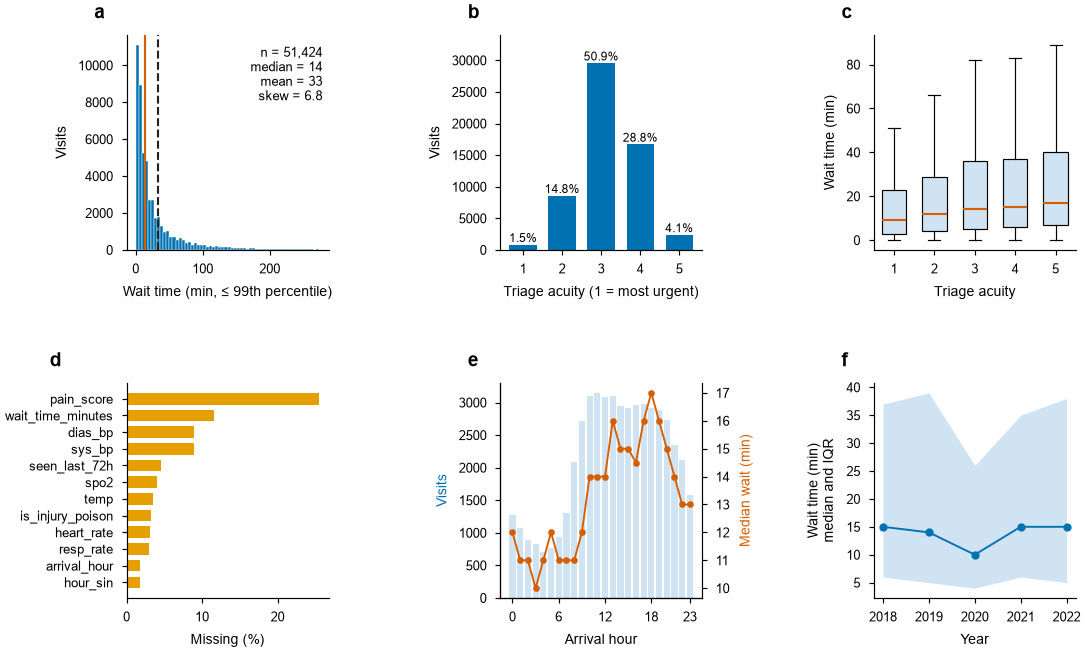

  → 저장: figures_nature\fig01_data_overview.png


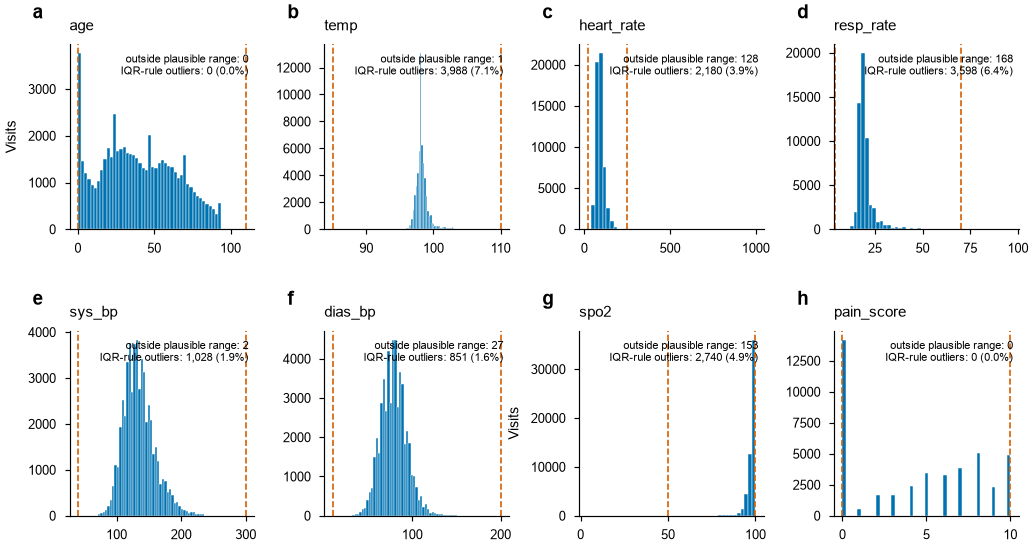

  → 저장: figures_nature\fig02_outlier_check.png


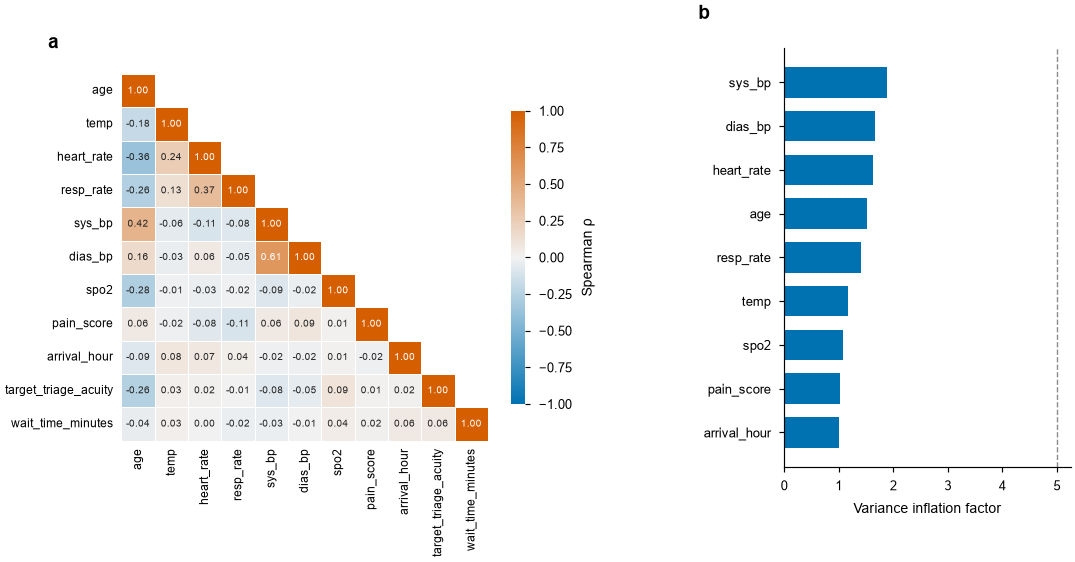

  → 저장: figures_nature\fig03_correlation_vif.png
VIF 표:


,age,temp,heart_rate,resp_rate,sys_bp,dias_bp,spo2,pain_score,arrival_hour
VIF,1.52,1.17,1.63,1.41,1.89,1.67,1.08,1.02,1.01


,variable,n,spearman_rho_with_wait,p_value
9,target_triage_acuity,51424,0.0648,0.0000
8,arrival_hour,51424,0.0630,0.0000
0,age,51424,-0.0404,0.0000
6,spo2,49501,0.0395,0.0000
4,sys_bp,47013,-0.0299,0.0000
1,temp,49796,0.0284,0.0000
3,resp_rate,50035,-0.0245,0.0000
7,pain_score,38722,0.0212,0.0000
5,dias_bp,46953,-0.0052,0.2620
2,heart_rate,50032,0.0006,0.8905



Kruskal–Wallis (대기시간 ~ 응급도 등급): H = 300.6, p = 7.95e-64, 효과크기 ε² = 0.006


,n,%
target_triage_acuity,,
1,846,1.46
2,8597,14.79
3,29568,50.87
4,16715,28.76
5,2398,4.13


가장 많은 등급 / 가장 적은 등급 비율(불균형 비): 35.0 : 1
'무조건 최빈 등급'만 찍어도 정확도: 50.9%  ← 이 숫자보다 높아야 의미가 있습니다
✔ 도구 준비 완료

5-1. 학습/시험 분할
학습 41,139건 | 시험 10,285건 | 학습 평균 대기시간 33.5분, 시험 평균 33.2분

5-2. 모델 학습 및 평가 (시험 데이터)
  Baseline      완료 (  9.8s)  R²=-0.000  MAE=32.9  RMSE=61.6
  Linear        완료 ( 10.6s)  R²=0.023  MAE=32.0  RMSE=60.9
  Ridge         완료 ( 12.0s)  R²=0.025  MAE=32.0  RMSE=60.9
  Lasso         완료 ( 28.7s)  R²=0.024  MAE=32.0  RMSE=60.9
  RandomForest  완료 (117.2s)  R²=0.043  MAE=31.8  RMSE=60.3
  XGBoost       완료 ( 32.0s)  R²=0.037  MAE=31.9  RMSE=60.5
  CatBoost      완료 ( 47.3s)  R²=0.048  MAE=31.6  RMSE=60.2

[표 A] 분석 A 모델별 성능 (시험 데이터)


,MAE (min) [95% CI],RMSE (min) [95% CI],R² [95% CI],R² (train),R² (log scale)
model,,,,,
Baseline,"32.9 [31.9, 33.9]","61.6 [55.9, 66.1]","-0.000 [-0.001, -0.000]",0.000,-0.407
Linear,"32.0 [31.1, 33.0]","60.9 [55.1, 65.4]","0.023 [0.016, 0.032]",0.033,-0.319
Ridge,"32.0 [31.0, 32.9]","60.9 [55.0, 65.4]","0.025 [0.018, 0.033]",0.032,-0.319
Lasso,"32.0 [31.0, 32.9]","60.9 [55.0, 65.4]","0.024 [0.017, 0.033]",0.030,-0.322
RandomForest,"31.8 [30.8, 32.8]","60.3 [54.2, 64.7]","0.043 [0.031, 0.059]",0.391,-0.313
XGBoost,"31.9 [30.9, 32.7]","60.5 [54.6, 64.8]","0.037 [0.022, 0.057]",0.298,-0.294
CatBoost,"31.6 [30.7, 32.5]","60.2 [54.2, 64.6]","0.048 [0.035, 0.067]",0.202,-0.310



▶ 시험 RMSE 기준 최고 모델: CatBoost   |   SHAP에 사용할 최고 트리 모델: CatBoost
  과적합 점검: CatBoost의 학습 R²(0.202) − 시험 R²(0.048) = 0.154  ← 차이가 큽니다(과적합 의심)
  Lasso가 0으로 만든 계수: 92 / 199 개, 선택된 alpha=0.03562


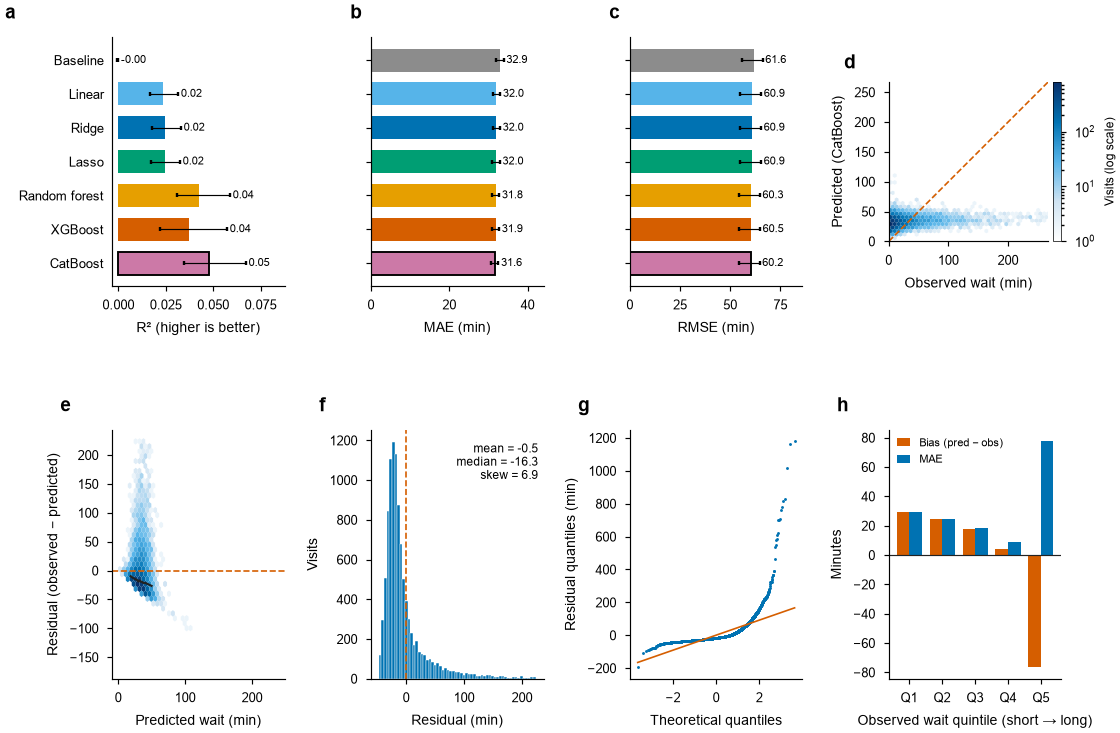

  → 저장: figures_nature\fig04_regression_performance.png
실제 대기시간 구간별 오차(분):


,bias,mae,ymed
q,,,
"(-0.001, 4.0]",29.0,29.0,2.0
"(4.0, 10.0]",24.6,24.6,7.0
"(10.0, 20.0]",18.0,18.1,15.0
"(20.0, 45.0]",3.8,9.1,30.0
"(45.0, 1213.0]",-76.6,77.5,83.0



5-3. 최고 모델의 변수 중요도
[순열 중요도 — CatBoost] 값 = 섞었을 때 증가한 RMSE(분)


,variable,importance,std
0,visit_month,0.932,0.156
1,region,0.659,0.048
2,seen_last_72h,0.495,0.013
3,insurance,0.234,0.034
4,ems_arrival,0.214,0.045
5,race,0.178,0.015
6,hour_sin,0.173,0.025
7,resp_rate,0.163,0.080
8,age,0.131,0.012
9,hour_cos,0.071,0.013



[모델 내장 중요도 — CatBoost (tree importance), 합계 100%로 정규화]


,%
chief_complaint_text,29.60
visit_month,13.29
region,7.55
seen_last_72h,5.33
hour_cos,4.38
race,3.81
resp_rate,3.27
hour_sin,3.20
ems_arrival,2.78
insurance,2.65



5-4. SHAP 계산 — CatBoost
  계산 방법: shap.TreeExplainer | 사용 환자 1,500명 | 변수(열) 199개
  SHAP 가법성 검증: 기준값 33.46, 환자간 편차 1.357e-14 → 통과 ✔
[원래 변수 단위 SHAP 평균 |값| (분)]


,mean|SHAP| (min)
region,2.945
visit_month,2.868
hour_sin,2.477
chief_complaint_text,2.300
ems_arrival,2.076
race,1.899
day_of_week,1.444
is_injury_poison,1.312
resp_rate,1.192
age,0.912


순열 중요도 ↔ SHAP 순위 일치도(스피어만 ρ) = 0.73  (1에 가까울수록 두 방법이 같은 변수를 중요하다고 봄)


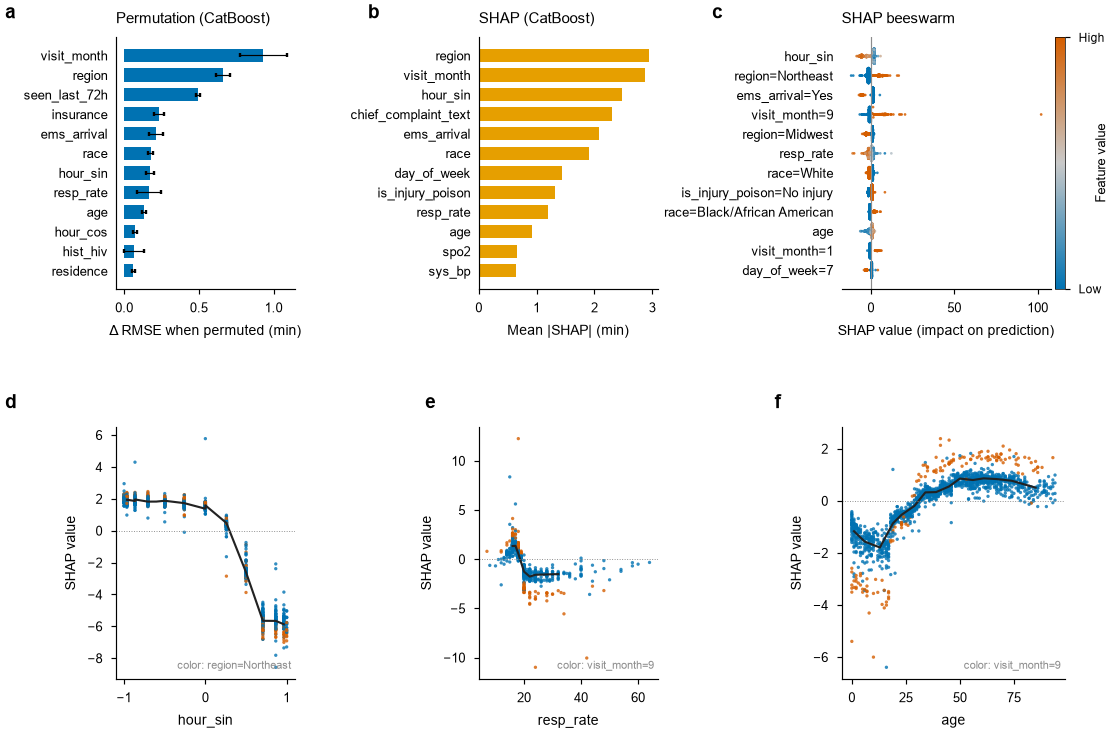

  → 저장: figures_nature\fig05_regression_importance_shap.png
[민감도 분석 — CatBoost]


,MAE,RMSE,R2
응급도 제외(기본),31.637,60.153,0.048
응급도 포함,31.581,60.104,0.049



6-1. 학습/시험 분할 (등급 비율을 유지하는 층화 분할)
학습 46,499건 | 시험 11,625건 | 등급 수 K=5
등급 비율(학습/시험): ([0.015, 0.148, 0.509, 0.288, 0.041], [0.015, 0.148, 0.509, 0.288, 0.041])

6-2. 모델 학습 및 평가 (시험 데이터)
  Baseline      완료 (  9.5s)  Macro-F1=0.135  BalAcc=0.200  QWK=0.000  Acc=0.509
  LogReg        완료 ( 39.7s)  Macro-F1=0.337  BalAcc=0.437  QWK=0.354  Acc=0.428
  OrdinalLogit  완료 (811.1s)  Macro-F1=0.229  BalAcc=0.244  QWK=0.196  Acc=0.538
    (의사결정나무 최적 하이퍼파라미터: {'model__max_depth': 10, 'model__min_samples_leaf': 30})
  DecisionTree  완료 ( 60.3s)  Macro-F1=0.297  BalAcc=0.384  QWK=0.330  Acc=0.369
  RandomForest  완료 ( 39.8s)  Macro-F1=0.402  BalAcc=0.388  QWK=0.457  Acc=0.576
  XGBoost       완료 (101.8s)  Macro-F1=0.406  BalAcc=0.466  QWK=0.443  Acc=0.515
  CatBoost      완료 (131.5s)  Macro-F1=0.379  BalAcc=0.469  QWK=0.418  Acc=0.478
✔ 자체 계산 지표가 scikit-learn 결과와 일치함을 확인했습니다.

[표 B] 분석 B 모델별 성능 (시험 데이터)


,Accuracy,Balanced_Acc,Macro_Precision,Macro_Recall,Macro_F1,QWK,LWK,Within1,AUC_macro,Under_triage,Over_triage
model,,,,,,,,,,,
Baseline,0.509,0.200,0.102,0.200,0.135,0.000,0.000,0.944,0.500,0.162,0.329
LogReg,0.428,0.437,0.354,0.437,0.337,0.354,0.299,0.810,0.742,0.291,0.280
OrdinalLogit,0.538,0.244,0.301,0.244,0.229,0.196,0.156,0.949,0.659,0.192,0.270
DecisionTree,0.369,0.384,0.320,0.384,0.297,0.330,0.252,0.793,0.691,0.346,0.286
RandomForest,0.576,0.388,0.468,0.388,0.402,0.457,0.389,0.946,0.769,0.245,0.179
XGBoost,0.515,0.466,0.393,0.466,0.406,0.443,0.377,0.897,0.769,0.266,0.219
CatBoost,0.478,0.469,0.374,0.469,0.379,0.418,0.352,0.867,0.766,0.282,0.240



[표 B-2] 95% 신뢰구간 포함


,Macro_F1,Balanced_Acc,QWK,Within1,Accuracy
model,,,,,
Baseline,"0.135 [0.133, 0.136]","0.200 [0.200, 0.200]","0.000 [0.000, 0.000]","0.944 [0.940, 0.948]","0.509 [0.498, 0.518]"
LogReg,"0.337 [0.330, 0.344]","0.437 [0.422, 0.455]","0.354 [0.340, 0.371]","0.810 [0.804, 0.817]","0.428 [0.420, 0.436]"
OrdinalLogit,"0.229 [0.223, 0.235]","0.244 [0.240, 0.248]","0.196 [0.181, 0.211]","0.949 [0.945, 0.953]","0.538 [0.527, 0.547]"
DecisionTree,"0.297 [0.287, 0.307]","0.384 [0.366, 0.403]","0.330 [0.316, 0.347]","0.793 [0.786, 0.800]","0.369 [0.360, 0.377]"
RandomForest,"0.402 [0.384, 0.419]","0.388 [0.376, 0.399]","0.457 [0.439, 0.475]","0.946 [0.942, 0.951]","0.576 [0.568, 0.584]"
XGBoost,"0.406 [0.392, 0.419]","0.466 [0.448, 0.484]","0.443 [0.426, 0.462]","0.897 [0.891, 0.903]","0.515 [0.506, 0.524]"
CatBoost,"0.379 [0.368, 0.388]","0.469 [0.453, 0.486]","0.418 [0.404, 0.434]","0.867 [0.861, 0.874]","0.478 [0.470, 0.486]"



▶ Macro_F1 기준 최고 모델: XGBoost   |   SHAP에 사용할 최고 트리 모델: XGBoost
  참고: '최빈 등급만 찍기' 기준선의 정확도 0.509, Macro-F1 0.135


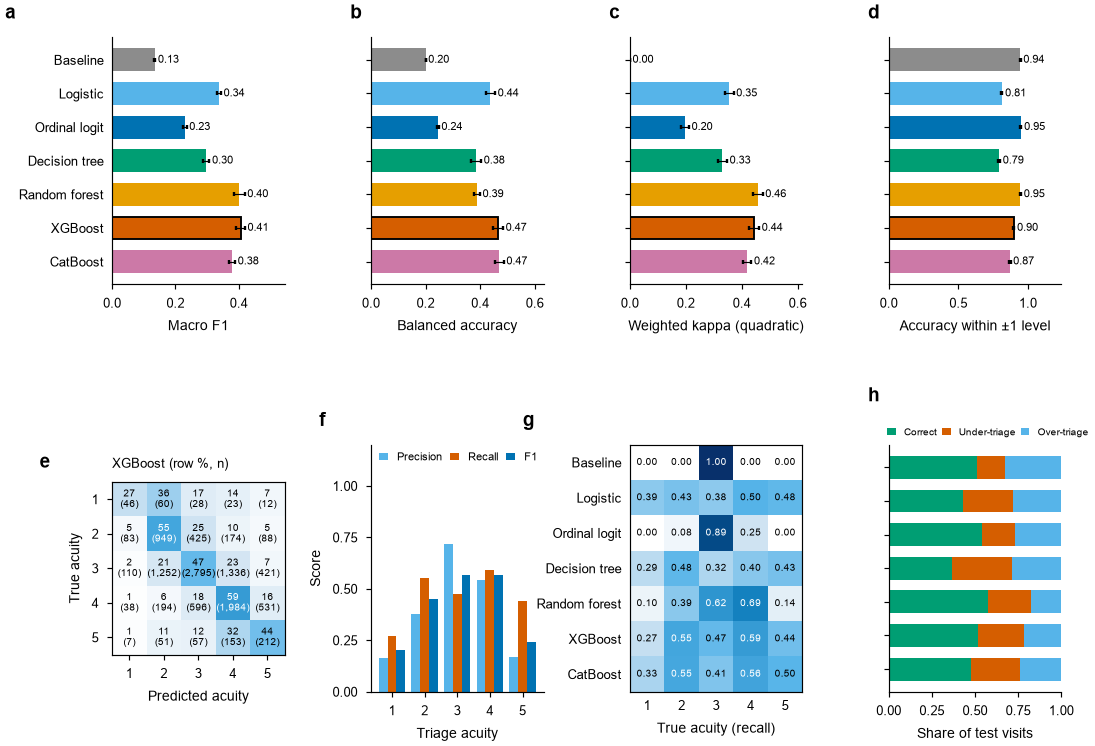

  → 저장: figures_nature\fig06_classification_performance.png

6-3. 최고 모델의 변수 중요도
[순열 중요도 — XGBoost] 값 = 섞었을 때 감소한 Macro F1


,variable,importance,std
0,chief_complaint_text,0.1315,0.0060
1,age,0.0348,0.0029
2,ems_arrival,0.0278,0.0036
3,heart_rate,0.0224,0.0024
4,visit_month,0.0205,0.0037
5,region,0.0174,0.0025
6,resp_rate,0.0098,0.0035
7,pain_score,0.0096,0.0024
8,sys_bp,0.0091,0.0020
9,is_injury_poison,0.0074,0.0011



[모델 내장 중요도 — XGBoost (tree importance), 합계 100%]


,%
chief_complaint_text,52.74
ems_arrival,7.35
visit_month,6.30
region,2.94
is_injury_poison,2.86
race,2.75
residence,2.72
day_of_week,2.01
temp,1.89
heart_rate,1.26



6-4. SHAP 계산 — XGBoost
  계산 방법: shap.TreeExplainer | 사용 환자 1,500명 | 변수(열) 190개 | 클래스 5개
[원래 변수 단위 SHAP 평균 |값| (로그오즈), 등급별]


,acuity_1,acuity_2,acuity_3,acuity_4,acuity_5
chief_complaint_text,0.658,0.508,0.442,0.527,0.591
ems_arrival,0.358,0.162,0.017,0.252,0.231
age,0.192,0.142,0.083,0.244,0.188
heart_rate,0.131,0.138,0.036,0.101,0.184
visit_month,0.289,0.038,0.032,0.043,0.085
pain_score,0.135,0.034,0.067,0.040,0.150
region,0.199,0.031,0.034,0.049,0.074
resp_rate,0.109,0.081,0.040,0.097,0.050
sys_bp,0.093,0.085,0.050,0.038,0.060
temp,0.147,0.031,0.031,0.034,0.060


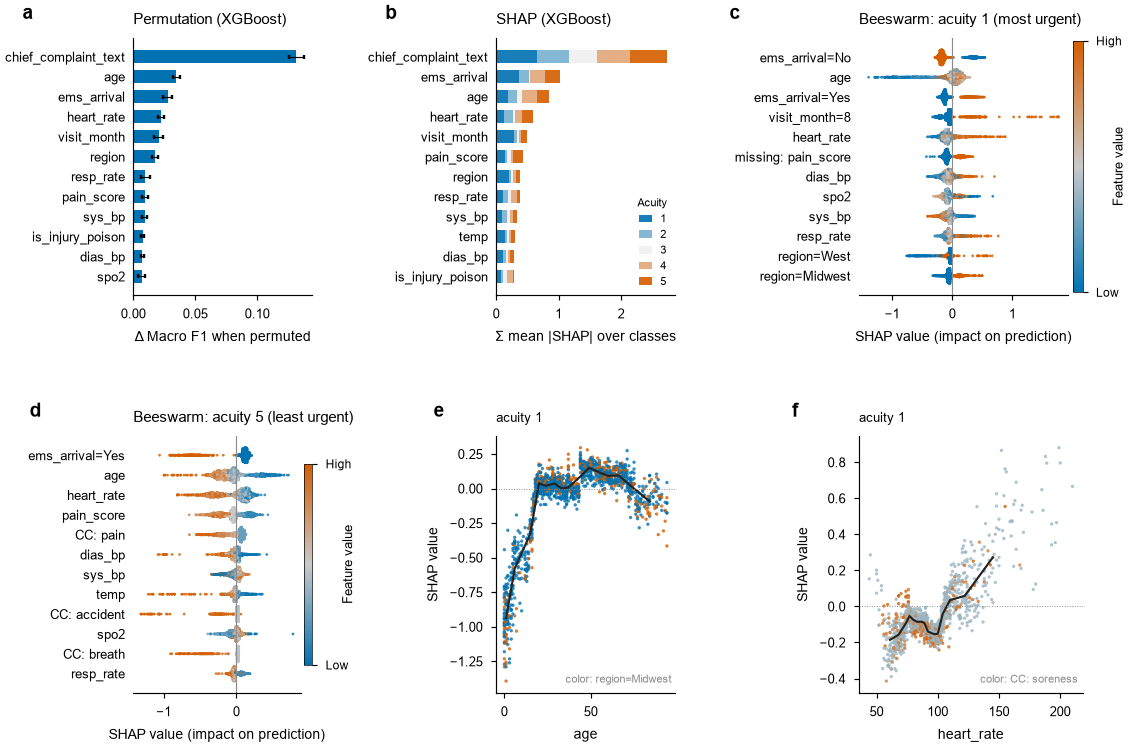

  → 저장: figures_nature\fig07_classification_importance_shap.png

7-1. 상호작용 분석


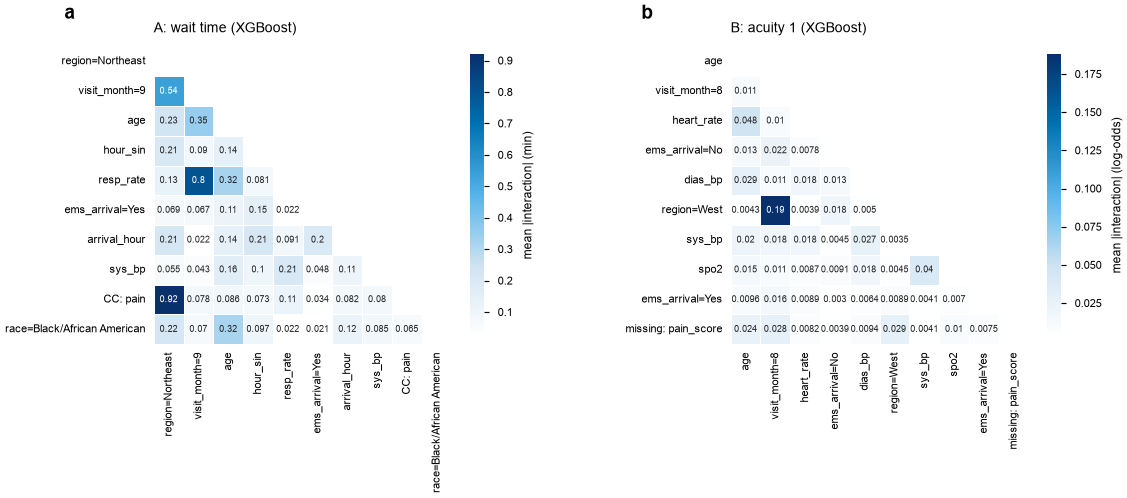

  → 저장: figures_nature\fig08_interactions.png
[A] 상위 상호작용 쌍:


,feature_1,feature_2,mean_abs_interaction
0,region=Northeast,CC: pain,0.9208
1,resp_rate,visit_month=9,0.7984
2,visit_month=9,seen_last_72h=1,0.6061
3,region=Northeast,seen_last_72h=1,0.5893
4,CC: cramps,CC: spasms,0.5725
5,region=Northeast,visit_month=9,0.5413
6,race=Hispanic,region=Northeast,0.5410
7,region=Northeast,visit_month=10,0.4093


[B] 상위 상호작용 쌍:


,feature_1,feature_2,mean_abs_interaction
0,region=West,visit_month=8,0.1881
1,region=Midwest,visit_month=10,0.0658
2,age,heart_rate,0.0483
3,sys_bp,spo2,0.0398
4,race=Hispanic,region=Northeast,0.0317
5,age,resp_rate,0.0297
6,age,dias_bp,0.0290
7,missing: pain_score,region=West,0.0288


공통 변수 41개 | A와 B의 중요도 순위 일치도(스피어만 ρ) = 0.77


,A_share_%,B_share_%,A_rank,B_rank,mean_rank
chief_complaint_text,9.35,27.219999,4.0,1.0,2.5
visit_month,11.66,4.860000,2.0,5.0,3.5
ems_arrival,8.44,10.180000,5.0,2.0,3.5
region,11.97,3.860000,1.0,7.0,4.0
age,3.71,8.480000,10.0,3.0,6.5
resp_rate,4.84,3.760000,9.0,8.0,8.5
pain_score,2.05,4.250000,13.0,6.0,9.5
is_injury_poison,5.33,2.790000,8.0,12.0,10.0
race,7.72,2.200000,6.0,14.0,10.0
hour_sin,10.07,1.200000,3.0,18.0,10.5


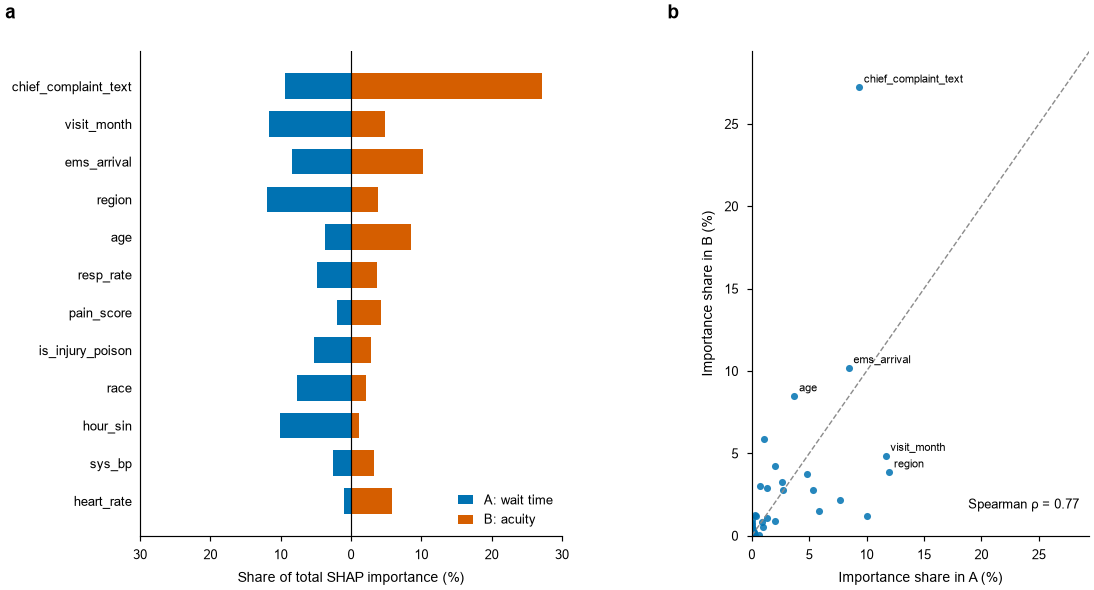

  → 저장: figures_nature\fig09_compare_A_vs_B.png

8. 자동 결과 요약
[분석 A: 대기시간 예측] 학습 41,139건 / 시험 10,285건
  · 최고 모델(시험 RMSE 기준): CatBoost — R²=0.048 [0.035, 0.067], MAE=31.6분, RMSE=60.2분
  · 평균으로 찍는 기준선 MAE=32.9분 → 최고 모델의 MAE 개선폭 1.3분
  · 순열 중요도 상위 5: visit_month, region, seen_last_72h, insurance, ems_arrival
  · SHAP 상위 5(원래 변수): region, visit_month, hour_sin, chief_complaint_text, ems_arrival
  · 응급도 포함 민감도 분석 R²: 0.049 (기본 0.048)

[분석 B: 응급도 분류] 학습 46,499건 / 시험 11,625건, 등급 5개
  · 최고 모델(Macro_F1 기준): XGBoost — Macro-F1=0.406 [0.392, 0.419], Balanced Acc=0.466, QWK=0.443, ±1등급 정확도=0.897, Accuracy=0.515
  · 과소분류율 26.6% / 과대분류율 21.9%
  · 순열 중요도 상위 5: chief_complaint_text, age, ems_arrival, heart_rate, visit_month
  · SHAP 상위 5(원래 변수): chief_complaint_text, ems_arrival, age, heart_rate, visit_month

[A vs B] 공통 변수 중요도 순위 일치도 ρ = 0.77

저장된 그림:
   figures_nature\fig01_data_overview.png
   figures_nature\fig02_outlier_check.png
   figures_nature\fig03_correlation_vif.png
   figures_nature\fig04_

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

In [1]:
# %% [markdown]
# # 응급실 데이터 분석 (NHAMCS 2018–2022)
# ## 분석 A: 대기시간 예측(회귀) · 분석 B: 중증도(응급도) 분류
#
# **이 노트북을 읽는 법 (비전공자용)**
# - 위에서 아래로 셀을 순서대로 실행(Shift+Enter)하면 됩니다.
# - 각 셀 위의 설명(마크다운)은 "이 셀이 무엇을 하는지"를 쉬운 말로 적은 것입니다.
# - 결과 그림은 `figures_nature/` 폴더에 PNG(300 dpi)와 PDF(벡터)로 자동 저장됩니다.
# - 결과 표는 `results/` 폴더에 CSV로 저장됩니다.
# - 이 코드는 **어떤 결과값도 미리 정해두지 않습니다.** 모든 숫자는 실행할 때 실제 데이터에서 계산됩니다.

# %% [markdown]
# ## 0. 준비: 라이브러리 설치 안내와 불러오기
#
# 아래 설치 명령은 **처음 한 번만**, 터미널(Anaconda Prompt) 또는 노트북 셀에서 실행합니다.
# ```
# pip install -U scikit-learn xgboost catboost shap statsmodels seaborn matplotlib pandas numpy scipy
# ```
# - scikit-learn **1.2 이상**을 권장합니다 (`pip show scikit-learn`으로 버전 확인).
# - 설치 후에는 Jupyter 커널을 한 번 재시작(Kernel → Restart)하세요.

# %%
import os, sys, re, time, warnings, logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.miscmodels.ordinal_model import OrderedModel

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, cohen_kappa_score,
                             roc_auc_score)

import xgboost as xgb
from xgboost import XGBRegressor, XGBClassifier
from catboost import CatBoostRegressor, CatBoostClassifier, Pool
import shap

# 경고 메시지 정리: 분석 결과에 영향이 없는 안내성 경고만 숨깁니다.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

print("pandas", pd.__version__, "| numpy", np.__version__)
import sklearn; print("scikit-learn", sklearn.__version__, "| xgboost", xgb.__version__, "| shap", shap.__version__)

# %% [markdown]
# ## 0-1. 분석 설정 (여기만 바꾸면 전체 분석이 바뀝니다)

# %%
# ───────── 분석 설정 ─────────
RANDOM_STATE   = 42       # 난수 고정: 같은 코드를 다시 돌려도 같은 결과가 나오게 합니다
TEST_SIZE      = 0.20     # 전체 데이터의 20%는 "시험 문제"(테스트셋)로 따로 보관합니다
SAMPLE_N       = None     # 빠른 연습용: 예) 20000 이면 2만 건만 사용. None 이면 전체 사용
N_JOBS         = -1       # 컴퓨터의 모든 CPU 코어를 사용
MISSING_CODES  = [-9, -8, -7]   # NHAMCS의 '결측/모름/해당없음' 코드. 숫자열에서 NaN(결측)으로 바꿉니다
VALID_ACUITY   = [1, 2, 3, 4, 5]  # 유효한 응급도 등급 (1=가장 급함 ... 5=가장 덜 급함)
HIGHER_IS_LESS_URGENT = True      # True: 숫자가 클수록 덜 급함(NHAMCS 기본). 데이터 코딩이 반대면 False
USE_CLASS_WEIGHT = True   # 분류에서 희귀 등급에 더 큰 가중치를 주어 불균형을 보정
BEST_CLF_METRIC = "Macro_F1"    # 최종 분류 모델 선택 기준: "Macro_F1" 또는 "QWK"
TFIDF_MAX_FEATURES = 100  # 주호소(chief_complaint_text)에서 뽑을 단어 개수
SHAP_SAMPLE    = 1500     # SHAP 계산에 쓸 테스트 환자 수 (계산량이 크므로 표본 사용)
PERM_SAMPLE    = 5000     # 순열 중요도 계산에 쓸 테스트 환자 수
BOOTSTRAP_B    = 200      # 성능지표 95% 신뢰구간용 부트스트랩 반복 횟수
ORDINAL_MAX_TRAIN = 20000 # 순서형 로지스틱은 느려서 학습 표본 상한을 둡니다
FIG_DIR = Path("figures_nature"); RES_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True); RES_DIR.mkdir(exist_ok=True)

rng_global = np.random.default_rng(RANDOM_STATE)

# %% [markdown]
# ## 0-2. 네이처(Nature) 스타일 그림 설정
#
# 네이처 계열 저널의 그림 규격을 따릅니다.
# - 폭: 단일 단 89 mm, 2단 183 mm / 글꼴: Arial(없으면 Helvetica, DejaVu Sans) 5–7 pt
# - 위·오른쪽 테두리 제거, 얇은 선(0.5 pt), 패널 라벨은 굵은 소문자 **a, b, c…**
# - 색맹 친화 팔레트(Okabe–Ito), 300 dpi PNG + 벡터 PDF 저장

# %%
MM = 1 / 25.4
W1, W15, W2 = 89 * MM, 120 * MM, 183 * MM   # 인치 단위 폭

OKABE = dict(blue="#0072B2", vermillion="#D55E00", green="#009E73", orange="#E69F00",
             sky="#56B4E9", purple="#CC79A7", yellow="#F0E442", black="#222222", grey="#8C8C8C")
CMAP_DIV = LinearSegmentedColormap.from_list("nat_div", [OKABE["blue"], "#F2F2F2", OKABE["vermillion"]])
CMAP_SEQ = LinearSegmentedColormap.from_list("nat_seq", ["#FFFFFF", "#CFE3F2", OKABE["sky"], OKABE["blue"], "#08306B"])
CMAP_FEAT = LinearSegmentedColormap.from_list("nat_feat", [OKABE["blue"], "#C9C9C9", OKABE["vermillion"]])

MODEL_COL = {"Baseline": OKABE["grey"], "Linear": OKABE["sky"], "Ridge": OKABE["blue"],
             "Lasso": OKABE["green"], "LogReg": OKABE["sky"], "OrdinalLogit": OKABE["blue"],
             "DecisionTree": OKABE["green"], "RandomForest": OKABE["orange"],
             "XGBoost": OKABE["vermillion"], "CatBoost": OKABE["purple"]}
MODEL_LABEL = {"Baseline": "Baseline", "Linear": "Linear", "Ridge": "Ridge", "Lasso": "Lasso",
               "LogReg": "Logistic", "OrdinalLogit": "Ordinal logit", "DecisionTree": "Decision tree",
               "RandomForest": "Random forest", "XGBoost": "XGBoost", "CatBoost": "CatBoost"}

def set_nature_style():
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 6, "axes.labelsize": 6, "axes.titlesize": 6.5, "axes.titleweight": "normal",
        "xtick.labelsize": 5.5, "ytick.labelsize": 5.5, "legend.fontsize": 5.5,
        "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
        "xtick.major.size": 2.2, "ytick.major.size": 2.2, "xtick.minor.size": 1.2, "ytick.minor.size": 1.2,
        "axes.spines.top": False, "axes.spines.right": False,
        "lines.linewidth": 0.8, "patch.linewidth": 0.5,
        "legend.frameon": False, "legend.handlelength": 1.2, "legend.borderpad": 0.2,
        "axes.axisbelow": True, "axes.grid": False,
        "figure.dpi": 170, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.03,
        "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
    })
set_nature_style()

def panel_label(ax, letter, dx=-0.16, dy=1.06):
    """패널 왼쪽 위에 굵은 소문자(a, b, c...) 표시"""
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom", ha="left")

def save_fig(fig, name):
    """PNG(300dpi)와 PDF(벡터)로 저장하고 화면에도 표시"""
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")
    plt.show()
    print(f"  → 저장: {FIG_DIR / (name + '.png')}")

def show(obj, rows=80):
    """표를 보기 좋게 출력 (Jupyter에서는 표, 일반 파이썬에서는 텍스트)"""
    try:
        from IPython.display import display
        with pd.option_context("display.max_rows", rows, "display.max_columns", 60, "display.width", 220):
            display(obj)
    except Exception:
        print(obj.to_string() if hasattr(obj, "to_string") else obj)

def banner(txt):
    print("\n" + "=" * 90 + f"\n{txt}\n" + "=" * 90)

# %% [markdown]
# ## 1. 데이터 구조 확인
#
# 데이터(`ER`)가 이미 불러와져 있다고 하셨으므로 그대로 사용합니다.
# 혹시 아직 불러오지 않았다면 아래 셀이 같은 이름(`ER`)으로 자동 불러옵니다.
# **원본 `ER`은 이 노트북 어디에서도 수정하지 않습니다.** (`df = ER.copy()` 로 복사본만 가공)

# %%
if "ER" not in globals():
    ER = pd.read_csv("nhamcs_data_2018_22.csv")

EXPECTED = ['visit_month','day_of_week','arrival_time','ems_arrival','vitals_during_visit','age','residence','sex',
            'insurance','no_payment','region','temp','heart_rate','resp_rate','sys_bp','dias_bp','spo2','pain_score',
            'seen_last_72h','episode','is_injury_poison','hist_alzheimers','hist_asthma','hist_cancer','hist_stroke',
            'hist_ckd','hist_copd','hist_chf','hist_cad','hist_depression','hist_diabetes_t1','hist_diabetes_t2',
            'hist_diabetes_unspec','hist_esrd','hist_pe','hist_hiv','hist_high_cholesterol','hist_hypertension',
            'hist_obesity','hist_sleep_apnea','hist_osteoporosis','hist_substance_abuse','intervention_iv_fluids',
            'target_triage_acuity','wait_time_minutes','race','year','chief_complaint_text','injury_cause_text']

banner("1-1. 데이터 크기와 변수명")
print(f"행(환자 방문 수): {ER.shape[0]:,}  |  열(변수 수): {ER.shape[1]}")
not_in_data = [c for c in EXPECTED if c not in ER.columns]
not_in_list = [c for c in ER.columns if c not in EXPECTED]
print("요청서에는 있으나 데이터에 없는 변수:", not_in_data if not_in_data else "없음")
print("데이터에는 있으나 요청서에 없는 변수:", not_in_list if not_in_list else "없음")
for must in ["wait_time_minutes", "target_triage_acuity"]:
    if must not in ER.columns:
        raise KeyError(f"종속변수 '{must}' 가 데이터에 없습니다. 변수명을 확인해 주세요.")
print("\n변수명 목록:", list(ER.columns))

banner("1-2. 변수별 데이터 타입")
dtype_tbl = pd.DataFrame({"dtype": ER.dtypes.astype(str), "n_unique": ER.nunique(dropna=True),
                          "example": [ER[c].dropna().iloc[0] if ER[c].notna().any() else None for c in ER.columns]})
show(dtype_tbl)

# %% [markdown]
# ## 1-3. 결측치 · 중복 · 기술통계 (원본 `ER`을 읽기만 합니다)
#
# NHAMCS 데이터는 "비어 있음"을 빈칸이 아니라 **-9(빈칸), -8(모름), -7(해당없음)** 같은 음수 코드로 적는 경우가 많습니다.
# 이 코드들은 진짜 값이 아니므로, 아래에서 개수를 먼저 확인한 뒤 전처리 단계에서 결측(NaN)으로 바꿉니다.

# %%
banner("1-3. 결측치 확인 (원본)")
num_cols_raw = [c for c in ER.columns if pd.api.types.is_numeric_dtype(ER[c])]
miss_raw = pd.DataFrame({
    "n_NaN(빈칸)": ER.isna().sum(),
    "n_코드결측(-9,-8,-7)": [int(ER[c].isin(MISSING_CODES).sum()) if c in num_cols_raw else 0 for c in ER.columns],
})
miss_raw["n_총결측"] = miss_raw.sum(axis=1)
miss_raw["총결측_%"] = (miss_raw["n_총결측"] / len(ER) * 100).round(2)
show(miss_raw.sort_values("총결측_%", ascending=False))

banner("1-4. 중복 행 확인")
n_dup = int(ER.duplicated().sum())
print(f"완전히 같은 행: {n_dup:,}건 ({n_dup/len(ER)*100:.3f}%)")
print("※ NHAMCS에는 환자 고유번호가 없어, 값이 모두 같은 행이 우연히 존재할 수 있습니다.")
print("  그래서 자동 삭제하지 않고 개수만 보고합니다. (삭제하려면 아래 DROP_DUPLICATES=True)")
DROP_DUPLICATES = False

banner("1-5. 수치형 변수 기술통계 (원본, 코드결측 포함 상태)")
desc = ER[num_cols_raw].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["skew"] = ER[num_cols_raw].skew()
show(desc.round(2))

# %% [markdown]
# ## 1-6. 범주형 변수 빈도표 · 종속변수 분포 (원본)

# %%
banner("1-6. 범주형 변수 빈도·비율 (각 변수 상위 8개 수준)")
CAT_PREVIEW = ['sex','race','residence','region','insurance','visit_month','day_of_week','ems_arrival',
               'is_injury_poison','seen_last_72h','year','vitals_during_visit','no_payment','episode']
rows = []
for c in [c for c in CAT_PREVIEW if c in ER.columns]:
    vc = ER[c].value_counts(dropna=False).head(8)
    for lvl, n in vc.items():
        rows.append((c, lvl, n, round(n / len(ER) * 100, 2)))
show(pd.DataFrame(rows, columns=["변수", "수준(값)", "n", "%"]), rows=200)

hist_cols_raw = [c for c in ER.columns if c.startswith("hist_")]
print("\n과거병력(hist_*) 변수의 '값' 분포 (1/0 형태인지 확인):")
show(pd.DataFrame({c: ER[c].value_counts(dropna=False) for c in hist_cols_raw[:6]}).T)

banner("1-7. 종속변수 원본 분포")
print("[target_triage_acuity] 원본 값 분포:")
show(ER["target_triage_acuity"].value_counts(dropna=False).sort_index().to_frame("n"))
print("\n[wait_time_minutes] 원본 요약:")
show(ER["wait_time_minutes"].describe(percentiles=[.05, .25, .5, .75, .95, .99]).to_frame("value").T.round(1))

# %% [markdown]
# ## 2. 전처리 (복사본 `df`에서만 수행)
#
# **원칙: "데이터에서 무언가를 학습하는 전처리"는 반드시 Pipeline 안에서 학습용 데이터로만 합니다.**
# (평균·중앙값 대체, 표준화, 단어 사전 등 → 시험 문제의 정보가 새어들어가는 것을 막기 위해)
#
# 그에 반해 아래는 데이터를 학습하지 않는 **고정 규칙 정리**라서 분할 전에 해도 안전합니다.
# 1. -9/-8/-7 같은 코드를 결측(NaN)으로 변환
# 2. 생리학적으로 불가능한 활력징후 값을 결측으로 변환 (삭제가 아님)
# 3. 응급도 등급이 1~5가 아닌 값(미분류 등)은 결측 처리
# 4. 도착시각을 "시(hour)"로 변환, 24시간 순환을 반영한 sin/cos 변수 생성
# 5. 범주형 변수는 문자열로 정리하고 결측은 'Missing'이라는 하나의 범주로 둠
# 6. 주호소 텍스트는 소문자로 정리 (단어 벡터화는 Pipeline 안에서)

# %%
banner("2-1. 복사본 생성 및 숫자형 변환")
df = ER.copy()                       # ← 원본 보존: 이후 모든 가공은 df에서만
if DROP_DUPLICATES:
    df = df.drop_duplicates().copy()

# 숫자여야 하는 변수가 문자열로 읽혔다면 숫자로 강제 변환(변환 불가 → NaN)
NUMERIC_RAW = ["age", "temp", "heart_rate", "resp_rate", "sys_bp", "dias_bp", "spo2", "pain_score",
               "wait_time_minutes", "target_triage_acuity"]
for c in NUMERIC_RAW:
    if c in df.columns and not pd.api.types.is_numeric_dtype(df[c]):
        before = df[c].notna().sum()
        df[c] = pd.to_numeric(df[c], errors="coerce")
        print(f"  {c}: 문자형 → 숫자형 변환 (변환 불가로 결측 처리된 값 {before - df[c].notna().sum():,}개)")

banner("2-2. -9/-8/-7 코드 → 결측(NaN)")
num_now = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
code_counts = {c: int(df[c].isin(MISSING_CODES).sum()) for c in num_now}
print({k: v for k, v in code_counts.items() if v > 0} or "코드결측 없음")
for c in num_now:
    df[c] = df[c].where(~df[c].isin(MISSING_CODES))

banner("2-3. 활력징후 단위 점검 및 생리학적 불가능 값 → 결측")
# 체온: NHAMCS는 98.6°F 를 986 처럼 소수점 없이 저장하는 경우가 있어 자동 점검합니다.
t_med = df["temp"].median()
if t_med > 200:
    df["temp"] = df["temp"] / 10.0
    print(f"  temp 중앙값이 {t_med:.0f} → 10으로 나누어 °F 단위로 보정")
t_med = df["temp"].median()
if t_med < 60:
    temp_range, temp_unit = (30, 45), "°C"
else:
    temp_range, temp_unit = (85, 110), "°F"
print(f"  temp 중앙값 {t_med:.1f} → 단위 {temp_unit} 로 판단, 허용범위 {temp_range}")

PLAUSIBLE = {"age": (0, 110), "temp": temp_range, "heart_rate": (20, 250), "resp_rate": (4, 70),
             "sys_bp": (40, 300), "dias_bp": (10, 200), "spo2": (50, 100), "pain_score": (0, 10)}
VITAL_COLS = ["temp", "heart_rate", "resp_rate", "sys_bp", "dias_bp", "spo2", "pain_score"]
raw_before_range = df[list(PLAUSIBLE)].copy()      # 그림(이상치 확인)용 보관
implausible_n = {}
for c, (lo, hi) in PLAUSIBLE.items():
    bad = (df[c] < lo) | (df[c] > hi)
    implausible_n[c] = int(bad.sum())
    df.loc[bad, c] = np.nan
show(pd.DataFrame({"허용범위": {c: PLAUSIBLE[c] for c in PLAUSIBLE},
                   "불가능값→결측 개수": implausible_n}))

banner("2-4. 종속변수 정리")
acu_raw = df["target_triage_acuity"]
bad_acu = acu_raw.notna() & ~acu_raw.isin(VALID_ACUITY)
print(f"응급도가 {VALID_ACUITY}가 아닌 값(미분류·기타) → 결측 처리: {int(bad_acu.sum()):,}건")
df["target_triage_acuity"] = acu_raw.where(acu_raw.isin(VALID_ACUITY))

w = df["wait_time_minutes"]
neg = (w < 0).sum()
df.loc[w < 0, "wait_time_minutes"] = np.nan
print(f"대기시간이 음수인 값 → 결측 처리: {int(neg):,}건")
print(f"대기시간 최댓값: {df['wait_time_minutes'].max():,.0f}분 (극단값은 지우지 않고 그대로 둡니다. 뒤에서 영향 점검)")

banner("2-5. 도착시각 → 시(hour) 변환")
def parse_arrival_hour(s):
    """도착시각을 0~23의 '시'로 변환. 형식(HHMM 숫자, 'HH:MM' 문자, 시 단위, 분 단위)을 자동 판별"""
    if not pd.api.types.is_numeric_dtype(s):
        as_num = pd.to_numeric(s, errors="coerce")
        if as_num.notna().mean() > 0.9:
            s = as_num
        else:
            ext = s.astype(str).str.extract(r"(\d{1,2})\s*:\s*(\d{2})")
            return pd.to_numeric(ext[0], errors="coerce"), "문자열 'HH:MM'"
    v = s.astype(float)
    vmax = v.max()
    if vmax <= 24:
        return np.floor(v), "이미 '시' 단위"
    if vmax <= 2359 and (v.dropna() % 100 < 60).all():
        return np.floor(v / 100), "HHMM 형식(예: 1435 = 14시 35분)"
    if vmax <= 1440:
        return np.floor(v / 60), "하루 중 경과 '분' 단위"
    return pd.Series(np.nan, index=s.index), "판별 불가"

hour, how = parse_arrival_hour(df["arrival_time"])
hour = hour.where((hour >= 0) & (hour <= 23))
print(f"arrival_time 해석: {how}  | 예시 원본값 {df['arrival_time'].dropna().iloc[:5].tolist()} → 시 {hour.dropna().iloc[:5].tolist()}")
print("※ 위 해석이 데이터 설명서와 다르면 알려주세요. (잘못 해석하면 시간 관련 결과가 틀어집니다)")
df["arrival_hour"] = hour
df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * hour / 24)

banner("2-6. 범주형·텍스트 변수 정리")
def clean_cat(s):
    """범주형 값을 깔끔한 문자열로 만들고 결측은 'Missing' 범주로 통일"""
    if pd.api.types.is_numeric_dtype(s):
        out = s.map(lambda v: "Missing" if pd.isna(v) else (str(int(v)) if float(v).is_integer() else str(v)))
    else:
        out = s.astype("object").map(lambda v: "Missing" if (pd.isna(v) or str(v).strip() == "") else str(v).strip())
    return out.astype(str)

HIST_COLS = [c for c in df.columns if c.startswith("hist_")]
CAT_COLS_A_ALL = ["sex", "race", "residence", "region", "insurance", "visit_month", "day_of_week", "ems_arrival",
                  "is_injury_poison", "seen_last_72h"] + HIST_COLS
CAT_COLS_A = [c for c in CAT_COLS_A_ALL if c in df.columns]
CAT_COLS_B = [c for c in CAT_COLS_A if c not in ("insurance", "seen_last_72h")]   # 분석 B 요청 변수 목록
NUM_COLS   = [c for c in ["age", "temp", "heart_rate", "resp_rate", "sys_bp", "dias_bp", "spo2", "pain_score",
                          "arrival_hour", "hour_sin", "hour_cos"] if c in df.columns]
TEXT_COL   = "chief_complaint_text"

# 결측 요약(전처리 후, 범주화 이전) – 그림 1d 용
miss_after = df[NUM_COLS + ["wait_time_minutes", "target_triage_acuity"]].isna().mean().mul(100)
for c in CAT_COLS_A:
    n_miss = (ER[c].isna() | (ER[c].isin(MISSING_CODES) if pd.api.types.is_numeric_dtype(ER[c]) else False)).mean() * 100
    miss_after[c] = n_miss

for c in CAT_COLS_A:
    df[c] = clean_cat(df[c])
if TEXT_COL in df.columns:
    df[TEXT_COL] = (df[TEXT_COL].astype("object").where(df[TEXT_COL].notna(), "").astype(str)
                    .str.lower().str.strip().replace({"nan": "", "none": ""}))
else:
    print(f"주의: {TEXT_COL} 열이 없어 텍스트 변수는 제외합니다.")

print("수치형 변수:", NUM_COLS)
print("범주형 변수(분석 A):", len(CAT_COLS_A), "개 / (분석 B):", len(CAT_COLS_B), "개  (hist_ 변수", len(HIST_COLS), "개 포함)")

# %% [markdown]
# ## 2-7. 분석용 데이터셋 만들기 + 누수(leakage) 점검
#
# - **분석 A (대기시간)**: `wait_time_minutes`가 있는 방문만 사용. 독립변수는 요청서 목록을 따르며,
#   `target_triage_acuity`는 기본 모델에서 **제외**합니다. (아래 "민감도 분석"에서 포함했을 때 어떻게 달라지는지 따로 확인)
# - **분석 B (중증도)**: `target_triage_acuity`가 1~5인 방문만 사용. 독립변수에서 대기시간·검사/처치 정보는 제외.
# - 두 분석 모두 `intervention_iv_fluids`(방문 중 처치), `episode`, `vitals_during_visit`, `no_payment`, `injury_cause_text`, `year`는
#   요청서의 독립변수 후보에 없거나 **방문 이후 정보**일 수 있어 모델에서 제외합니다. (`year`는 탐색 그림에만 사용)

# %%
dfA = df[df["wait_time_minutes"].notna()].copy()
dfB = df[df["target_triage_acuity"].notna()].copy()
if SAMPLE_N:
    dfA = dfA.sample(min(SAMPLE_N, len(dfA)), random_state=RANDOM_STATE)
    dfB = dfB.sample(min(SAMPLE_N, len(dfB)), random_state=RANDOM_STATE)
    print(f"※ 빠른 연습 모드: 각 분석 최대 {SAMPLE_N:,}건만 사용")

FEATS_A = NUM_COLS + CAT_COLS_A + ([TEXT_COL] if TEXT_COL in df.columns else [])
FEATS_B = NUM_COLS + CAT_COLS_B + ([TEXT_COL] if TEXT_COL in df.columns else [])

# 누수 점검: 종속변수나 사후정보가 독립변수에 섞이지 않았는지 코드로 확인
FORBIDDEN = {"wait_time_minutes", "target_triage_acuity", "intervention_iv_fluids", "injury_cause_text",
             "episode", "vitals_during_visit", "no_payment", "year"}
assert not (set(FEATS_A) & FORBIDDEN), f"분석 A 누수 변수 발견: {set(FEATS_A) & FORBIDDEN}"
assert not (set(FEATS_B) & FORBIDDEN), f"분석 B 누수 변수 발견: {set(FEATS_B) & FORBIDDEN}"
print("✔ 누수 점검 통과: 종속변수·사후정보가 독립변수에 포함되지 않았습니다.")
print(f"분석 A: {len(dfA):,}건, 독립변수 {len(FEATS_A)}개  |  분석 B: {len(dfB):,}건, 독립변수 {len(FEATS_B)}개")
# %% [markdown]
# ## 3. 탐색적 데이터 분석(EDA) — 그림으로 데이터 이해하기
#
# ### 그림 1. 데이터 개요
# - **a** 대기시간은 대부분 짧고 일부만 매우 긴 "오른쪽으로 긴 꼬리" 모양인지 확인
# - **b** 응급도 등급별 환자 비율(클래스 불균형 확인)
# - **c** 응급도 등급별 대기시간 (급한 환자가 더 빨리 보이는지)
# - **d** 결측이 많은 변수 (모델이 이 변수들을 얼마나 믿을 수 있는지 가늠)
# - **e** 도착 시각별 환자 수(막대)와 중앙 대기시간(선)
# - **f** 연도별 중앙 대기시간 (코로나 시기 변화 확인 – 탐색용이며 모델에는 넣지 않음)

# %%
set_nature_style()
CLASS_LEVELS = sorted(dfB["target_triage_acuity"].unique().astype(int))
CLASS_NAME = {1: "1 Immediate", 2: "2 Emergent", 3: "3 Urgent", 4: "4 Semi-urgent", 5: "5 Non-urgent"}
cls_label = lambda k: CLASS_NAME.get(k, str(k))

fig = plt.figure(figsize=(W2, 4.3))
gs = GridSpec(2, 3, figure=fig, hspace=0.62, wspace=0.85)

# a) 대기시간 분포
ax = fig.add_subplot(gs[0, 0]); panel_label(ax, "a")
wv = dfA["wait_time_minutes"]
p99 = wv.quantile(0.99)
ax.hist(wv[wv <= p99], bins=60, color=OKABE["blue"], edgecolor="white", linewidth=0.2)
ax.axvline(wv.median(), color=OKABE["vermillion"], lw=0.9)
ax.axvline(wv.mean(), color=OKABE["black"], lw=0.9, ls="--")
ax.set_xlabel("Wait time (min, ≤ 99th percentile)"); ax.set_ylabel("Visits")
ax.text(0.97, 0.95, f"n = {len(wv):,}\nmedian = {wv.median():.0f}\nmean = {wv.mean():.0f}\nskew = {wv.skew():.1f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=5.3)

# b) 응급도 분포
ax = fig.add_subplot(gs[0, 1]); panel_label(ax, "b")
vc = dfB["target_triage_acuity"].astype(int).value_counts().reindex(CLASS_LEVELS)
bars = ax.bar([str(k) for k in vc.index], vc.values, color=OKABE["blue"], width=0.7)
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v / vc.sum() * 100:.1f}%", ha="center", va="bottom", fontsize=5.2)
ax.set_xlabel("Triage acuity (1 = most urgent)"); ax.set_ylabel("Visits")
ax.set_ylim(0, vc.max() * 1.15)

# c) 응급도별 대기시간 박스플롯
ax = fig.add_subplot(gs[0, 2]); panel_label(ax, "c")
both = df.dropna(subset=["wait_time_minutes", "target_triage_acuity"])
data_box = [both.loc[both["target_triage_acuity"] == k, "wait_time_minutes"].values for k in CLASS_LEVELS]
bp = ax.boxplot(data_box, positions=range(len(CLASS_LEVELS)), widths=0.6, showfliers=False, patch_artist=True,
                medianprops=dict(color=OKABE["vermillion"], lw=0.9), whiskerprops=dict(lw=0.5), capprops=dict(lw=0.5),
                boxprops=dict(lw=0.5))
for p in bp["boxes"]:
    p.set_facecolor("#CFE3F2")
ax.set_xticks(range(len(CLASS_LEVELS))); ax.set_xticklabels([str(k) for k in CLASS_LEVELS])
ax.set_xlabel("Triage acuity"); ax.set_ylabel("Wait time (min)")

# d) 결측 상위 변수
ax = fig.add_subplot(gs[1, 0]); panel_label(ax, "d", dx=-0.38)
ms = miss_after[miss_after > 0].sort_values(ascending=False).head(12)[::-1]
if len(ms):
    ax.barh(range(len(ms)), ms.values, color=OKABE["orange"], height=0.7)
    ax.set_yticks(range(len(ms))); ax.set_yticklabels(ms.index)
    ax.set_xlabel("Missing (%)")
else:
    ax.text(0.5, 0.5, "No missing values", ha="center", transform=ax.transAxes)

# e) 시간대별 환자 수 & 중앙 대기시간
ax = fig.add_subplot(gs[1, 1]); panel_label(ax, "e")
h = dfA.dropna(subset=["arrival_hour"])
cnt = h.groupby("arrival_hour").size().reindex(range(24), fill_value=0)
med = h.groupby("arrival_hour")["wait_time_minutes"].median().reindex(range(24))
ax.bar(range(24), cnt.values, color="#CFE3F2", width=0.8)
ax.set_xlabel("Arrival hour"); ax.set_ylabel("Visits", color=OKABE["blue"])
ax.set_xticks([0, 6, 12, 18, 23])
ax2 = ax.twinx(); ax2.spines["right"].set_visible(True)
ax2.plot(range(24), med.values, color=OKABE["vermillion"], marker="o", ms=1.8)
ax2.set_ylabel("Median wait (min)", color=OKABE["vermillion"])

# f) 연도별 대기시간
ax = fig.add_subplot(gs[1, 2]); panel_label(ax, "f")
if "year" in dfA.columns and dfA["year"].notna().any():
    g = dfA.groupby("year")["wait_time_minutes"]
    q = pd.DataFrame({"q1": g.quantile(.25), "med": g.median(), "q3": g.quantile(.75)})
    ax.fill_between(q.index, q["q1"], q["q3"], color="#CFE3F2", lw=0)
    ax.plot(q.index, q["med"], color=OKABE["blue"], marker="o", ms=2.5)
    ax.set_xticks(q.index); ax.set_xlabel("Year"); ax.set_ylabel("Wait time (min)\nmedian and IQR")
else:
    ax.text(0.5, 0.5, "'year' not available", ha="center", transform=ax.transAxes)
save_fig(fig, "fig01_data_overview")

# %% [markdown]
# ### 그림 2. 이상치(극단값) 점검 — 지우지 않고 원인부터 확인
#
# 빨간 점선은 "사람에게 생리학적으로 가능한 범위"입니다. 이 범위를 벗어난 값은 **입력 오류·코드 값일 가능성이 높아** 결측으로 바꿨지만,
# 범위 안에서 크거나 작은 값(예: 매우 빠른 심박수)은 **진짜 위중한 환자일 수 있으므로 그대로 둡니다.**
# 대기시간의 긴 꼬리도 실제 현상일 수 있어 삭제하지 않습니다.

# %%
vars_plot = list(PLAUSIBLE)
fig, axes = plt.subplots(2, 4, figsize=(W2, 3.6))
fig.subplots_adjust(hspace=0.55, wspace=0.38)
for ax, v, lab in zip(axes.ravel(), vars_plot, "abcdefgh"):
    x = raw_before_range[v].dropna()
    lo, hi = PLAUSIBLE[v]
    zoom = x[(x >= x.quantile(0.001)) & (x <= x.quantile(0.999))]
    ax.hist(zoom, bins=45, color=OKABE["blue"], edgecolor="white", linewidth=0.2)
    ax.axvline(lo, color=OKABE["vermillion"], ls="--", lw=0.7); ax.axvline(hi, color=OKABE["vermillion"], ls="--", lw=0.7)
    q1, q3 = x.quantile(.25), x.quantile(.75); iqr = q3 - q1
    n_iqr = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())
    ax.set_title(v, loc="left", fontsize=6.3)
    ax.text(0.97, 0.95, f"outside plausible range: {implausible_n[v]:,}\nIQR-rule outliers: {n_iqr:,} ({n_iqr / max(len(x), 1) * 100:.1f}%)",
            transform=ax.transAxes, ha="right", va="top", fontsize=4.6)
    ax.set_ylabel("Visits" if v in ("age", "spo2") else "")
    panel_label(ax, lab, dx=-0.2, dy=1.12)
save_fig(fig, "fig02_outlier_check")

# %% [markdown]
# ### 그림 3. 변수 간 상관관계와 다중공선성
#
# - **a** 스피어만 순위상관계수 (−1~+1). 값이 클수록 함께 움직이는 변수입니다. (상관 ≠ 인과)
# - **b** VIF: 같은 정보를 중복해서 담은 정도. 보통 5~10 이상이면 선형모델 계수 해석에 주의가 필요합니다.
#   (트리 계열 모델은 영향이 작지만, 변수 중요도가 비슷한 변수 사이에 나뉘어 보일 수 있습니다.)

# %%
corr_cols = [c for c in ["age", "temp", "heart_rate", "resp_rate", "sys_bp", "dias_bp", "spo2", "pain_score",
                         "arrival_hour", "target_triage_acuity", "wait_time_minutes"] if c in df.columns]
corr = df[corr_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

# VIF: 수치형 독립변수만, 결측은 중앙값 대체 후 계산
vif_cols = [c for c in ["age", "temp", "heart_rate", "resp_rate", "sys_bp", "dias_bp", "spo2", "pain_score", "arrival_hour"] if c in df.columns]
Xv = df[vif_cols].fillna(df[vif_cols].median())
Xv = sm.add_constant(Xv)
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=vif_cols)

fig = plt.figure(figsize=(W2, 3.2))
gs = GridSpec(1, 2, figure=fig, width_ratios=[1.6, 1], wspace=0.55)
ax = fig.add_subplot(gs[0]); panel_label(ax, "a", dx=-0.2)
sns.heatmap(corr, mask=mask, cmap=CMAP_DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 4.3},
            linewidths=0.4, linecolor="white", cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax, square=True)
ax.tick_params(labelsize=5, length=0)
ax = fig.add_subplot(gs[1]); panel_label(ax, "b", dx=-0.3)
vs = vif.sort_values()
ax.barh(vs.index, vs.values, color=[OKABE["vermillion"] if v >= 5 else OKABE["blue"] for v in vs.values], height=0.7)
ax.axvline(5, color=OKABE["grey"], ls="--", lw=0.6)
ax.set_xlabel("Variance inflation factor")
save_fig(fig, "fig03_correlation_vif")
print("VIF 표:"); show(vif.round(2).to_frame("VIF").T)

# %% [markdown]
# ### 3-1. 간단한 통계 검정 (EDA용)
# - 대기시간과 각 수치형 변수의 스피어만 상관계수·p값
# - 응급도 등급에 따라 대기시간 분포가 다른지 Kruskal–Wallis 검정 (정규분포를 가정하지 않는 방법)
# - 표본이 매우 크면 아주 작은 차이도 "유의"하게 나오므로 **효과크기**(ε²)를 함께 봅니다.

# %%
rows = []
for c in [c for c in NUM_COLS if c not in ("hour_sin", "hour_cos")] + ["target_triage_acuity"]:
    d = df[[c, "wait_time_minutes"]].dropna()
    if len(d) > 30:
        rho, p = stats.spearmanr(d[c], d["wait_time_minutes"])
        rows.append((c, len(d), rho, p))
sp_tbl = pd.DataFrame(rows, columns=["variable", "n", "spearman_rho_with_wait", "p_value"]).sort_values("spearman_rho_with_wait", key=abs, ascending=False)
show(sp_tbl.round(4))
sp_tbl.to_csv(RES_DIR / "eda_spearman_with_wait.csv", index=False)

groups = [g["wait_time_minutes"].values for _, g in both.groupby("target_triage_acuity") if len(g) > 1]
H, p_kw = stats.kruskal(*groups)
eps2 = (H - len(groups) + 1) / (len(both) - len(groups))
print(f"\nKruskal–Wallis (대기시간 ~ 응급도 등급): H = {H:,.1f}, p = {p_kw:.3g}, 효과크기 ε² = {eps2:.3f}")

# %% [markdown]
# ### 3-2. 클래스 불균형 확인 (분석 B)
# 등급별 비율이 크게 다르면, "대부분을 흔한 등급으로 찍는" 모델도 정확도(Accuracy)가 높게 나올 수 있습니다.
# 그래서 이 분석에서는 Macro F1, Balanced Accuracy, Weighted Kappa를 함께 봅니다.

# %%
imb = dfB["target_triage_acuity"].astype(int).value_counts().sort_index()
imb_tbl = pd.DataFrame({"n": imb, "%": (imb / imb.sum() * 100).round(2)})
show(imb_tbl)
print(f"가장 많은 등급 / 가장 적은 등급 비율(불균형 비): {imb.max() / imb.min():.1f} : 1")
print(f"'무조건 최빈 등급'만 찍어도 정확도: {imb.max() / imb.sum() * 100:.1f}%  ← 이 숫자보다 높아야 의미가 있습니다")
# %% [markdown]
# ## 4. 분석 도구 만들기 (전처리 Pipeline · 평가지표 · 해석 도구)
#
# 이 장은 "도구 상자"입니다. 실행해도 눈에 보이는 결과는 없고, 이후 분석 A·B에서 공통으로 사용합니다.
#
# **Pipeline이란?** 전처리(결측 대체 → 표준화 → 원-핫 인코딩 → 단어 벡터화)와 모델을 하나로 묶은 "조립 라인"입니다.
# 학습용 데이터로만 전처리 규칙(예: 중앙값, 평균, 단어 사전)을 배우고, 시험용 데이터에는 그 규칙을 **적용만** 하므로
# 시험 문제의 정보가 학습에 새어들어가는 일(데이터 누수)이 구조적으로 막힙니다.
#
# | 전처리 | 대상 | 하는 일 |
# |---|---|---|
# | SimpleImputer(median) + 결측표시 열 | 수치형 | 빈칸을 학습셋 중앙값으로 채우고, "원래 비어 있었는지"를 별도 열로 남김 |
# | StandardScaler | 수치형 | 평균 0, 표준편차 1로 맞춤 (선형모델의 공정한 비교를 위해) |
# | OneHotEncoder | 범주형 | 범주를 0/1 열로 펼침, 희귀 범주(30건 미만)는 하나로 묶음 |
# | TfidfVectorizer | 주호소 텍스트 | 자주 나오되 너무 흔하지 않은 단어 상위 100개를 숫자로 변환 |

# %%
def build_preprocessor(num_cols, cat_cols, text_col=TEXT_COL, use_text=True, drop_first=False):
    """수치/범주/텍스트를 한 번에 처리하는 ColumnTransformer 생성"""
    transformers = [
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), list(num_cols)),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30,
                              drop="first" if drop_first else "if_binary", sparse_output=False), list(cat_cols)),
    ]
    if use_text and text_col in df.columns:
        transformers.append(("txt", TfidfVectorizer(max_features=TFIDF_MAX_FEATURES, min_df=10, stop_words="english",
                                                     sublinear_tf=True, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b"), text_col))
    # sparse_threshold=0 → 항상 일반(dense) 배열로 출력 (XGBoost/CatBoost/SHAP 호환)
    return ColumnTransformer(transformers, sparse_threshold=0, verbose_feature_names_out=True)

# ── 변수 이름 정리 도구 ──
def _cat_group(b, cat_cols):
    cands = [c for c in cat_cols if b.startswith(c + "_")]
    return max(cands, key=len) if cands else None

def pretty_names(names, cat_cols):
    """'cat__sex_1' → 'sex=1', 'txt__pain' → 'CC: pain'"""
    out = []
    for n in names:
        if n.startswith("txt__"):
            out.append("CC: " + n[5:])
        elif n.startswith("num__"):
            b = n[5:]
            out.append("missing: " + b[len("missingindicator_"):] if b.startswith("missingindicator_") else b)
        elif n.startswith("cat__"):
            b = n[5:]; g = _cat_group(b, cat_cols)
            out.append(f"{g}={b[len(g) + 1:]}" if g else b)
        else:
            out.append(n)
    return out

def feature_groups(names, cat_cols):
    """펼쳐진 열을 원래 변수 이름으로 되돌리는 매핑 (예: cat__sex_1 → sex)"""
    out = []
    for n in names:
        if n.startswith("txt__"):
            out.append("chief_complaint_text")
        elif n.startswith("num__"):
            b = n[5:]
            out.append(b[len("missingindicator_"):] if b.startswith("missingindicator_") else b)
        elif n.startswith("cat__"):
            b = n[5:]; g = _cat_group(b, cat_cols); out.append(g if g else b)
        else:
            out.append(n)
    return np.array(out)

def raw_col_of(name):
    """수치 변수의 원래 열 이름 (그림에서 원래 단위로 표시하기 위함)"""
    if name.startswith("num__") and not name[5:].startswith("missingindicator_"):
        return name[5:]
    return None

# %% [markdown]
# ### 4-1. 평가지표 함수
# - **회귀**: MAE(평균 절대 오차, 분 단위), RMSE(큰 오차에 더 민감), R²(1에 가까울수록 설명력 높음, 0이면 평균으로 찍는 것과 동일)
# - **분류**: Accuracy, Macro Precision/Recall/F1(등급별 지표의 단순평균 → 희귀 등급도 동등하게 반영),
#   Balanced Accuracy(등급별 재현율 평균), **Weighted Cohen's Kappa**(등급이 순서형이므로 "1등급을 5등급으로 틀린 것"을
#   "1등급을 2등급으로 틀린 것"보다 더 큰 오류로 계산),
#   그리고 임상적으로 의미 있는 **±1등급 이내 정확도**, **과소분류율**(실제보다 덜 급하다고 분류), **과대분류율**.
# - 모든 지표에는 테스트셋을 다시 뽑는 **부트스트랩 95% 신뢰구간**을 붙여 "우연한 차이"인지 가늠할 수 있게 합니다.

# %%
def reg_metrics(y, p):
    p = np.clip(p, 0, None)                    # 대기시간은 음수가 될 수 없으므로 0으로 하한
    return dict(MAE=mean_absolute_error(y, p), RMSE=np.sqrt(mean_squared_error(y, p)), R2=r2_score(y, p),
                MedAE=float(np.median(np.abs(y - p))), R2_log=r2_score(np.log1p(y), np.log1p(p)))

def boot_reg(y, p, B=BOOTSTRAP_B, seed=RANDOM_STATE):
    y = np.asarray(y, float); p = np.clip(np.asarray(p, float), 0, None)
    rng = np.random.default_rng(seed); n = len(y); out = {"MAE": [], "RMSE": [], "R2": []}
    for _ in range(B):
        i = rng.integers(0, n, n); yy, pp = y[i], p[i]
        out["MAE"].append(np.mean(np.abs(yy - pp)))
        out["RMSE"].append(np.sqrt(np.mean((yy - pp) ** 2)))
        out["R2"].append(1 - np.sum((yy - pp) ** 2) / np.sum((yy - yy.mean()) ** 2))
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in out.items()}

def cm_from(y, p, K):
    return np.bincount(np.asarray(y) * K + np.asarray(p), minlength=K * K).reshape(K, K)

def clf_from_cm(cm):
    """혼동행렬(cm[실제, 예측])에서 모든 분류지표를 한 번에 계산 (부트스트랩을 빠르게 하기 위함)"""
    K = cm.shape[0]; n = cm.sum(); tp = np.diag(cm).astype(float)
    rec = tp / np.maximum(cm.sum(1), 1); prec = tp / np.maximum(cm.sum(0), 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0.0)
    i, j = np.indices((K, K))
    E = np.outer(cm.sum(1), cm.sum(0)) / n
    wq = (i - j) ** 2 / max((K - 1) ** 2, 1); wl = np.abs(i - j) / max(K - 1, 1)
    qwk = 1 - (wq * cm).sum() / (wq * E).sum(); lwk = 1 - (wl * cm).sum() / (wl * E).sum()
    pred_higher = cm[j > i].sum() / n      # 예측 번호가 더 큼(실제보다 '덜 급함' 쪽으로 틀림)
    pred_lower  = cm[j < i].sum() / n
    under, over = (pred_higher, pred_lower) if HIGHER_IS_LESS_URGENT else (pred_lower, pred_higher)
    return dict(Accuracy=tp.sum() / n, Balanced_Acc=rec.mean(), Macro_Precision=prec.mean(), Macro_Recall=rec.mean(),
                Macro_F1=f1.mean(), QWK=qwk, LWK=lwk, Within1=cm[np.abs(i - j) <= 1].sum() / n,
                Under_triage=under, Over_triage=over, per_class=dict(precision=prec, recall=rec, f1=f1))

def boot_clf(y, p, K, B=BOOTSTRAP_B, seed=RANDOM_STATE, keys=("Macro_F1", "Balanced_Acc", "QWK", "Within1", "Accuracy")):
    y = np.asarray(y); p = np.asarray(p); rng = np.random.default_rng(seed); n = len(y)
    res = {k: [] for k in keys}
    for _ in range(B):
        i = rng.integers(0, n, n); m = clf_from_cm(cm_from(y[i], p[i], K))
        for k in keys: res[k].append(m[k])
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in res.items()}

def perm_importance_df(pipe, X, y, scoring, n=PERM_SAMPLE, n_repeats=5):
    """순열 중요도: 한 변수의 값을 무작위로 섞었을 때 성능이 얼마나 나빠지는가 (원래 변수 단위)"""
    idx = X.sample(min(n, len(X)), random_state=RANDOM_STATE).index
    r = permutation_importance(pipe, X.loc[idx], y.loc[idx], scoring=scoring, n_repeats=n_repeats,
                               random_state=RANDOM_STATE, n_jobs=1)
    return pd.DataFrame({"variable": X.columns, "importance": r.importances_mean, "std": r.importances_std}
                        ).sort_values("importance", ascending=False).reset_index(drop=True)

# %% [markdown]
# ### 4-2. SHAP 도구
#
# **SHAP이란?** 각 환자의 예측값이 "평균적인 환자의 예측"에서 출발해, 변수들이 각각 얼마나 올리고(+) 내렸는지(−)를
# 더하기로 분해해 보여주는 방법입니다. 값이 클수록 그 변수가 그 환자의 예측에 큰 영향을 준 것입니다.
# - SHAP은 "모델이 어떤 변수에 의존하는가"를 설명할 뿐 **"그 변수를 바꾸면 결과가 바뀐다"는 인과관계를 의미하지 않습니다.**
# - 계산량이 커서 테스트 환자 일부(`SHAP_SAMPLE`)를 무작위로 뽑아 계산합니다.
# - SHAP 값은 전처리된 열(예: `sex=2`, `CC: pain`) 단위로 계산한 뒤, **원래 변수 단위로 합쳐서**(예: sex 전체) 다시 보여줍니다.

# %%
TREE_MODELS = ("RandomForest", "XGBoost", "CatBoost")

def _to_nfk(sv, n_feat):
    """shap/모델 버전마다 다른 출력 모양을 (환자수, 변수수, 클래스수)로 통일"""
    if isinstance(sv, list):
        sv = np.stack([np.asarray(a) for a in sv], axis=-1)
    sv = np.asarray(sv)
    if sv.ndim == 2:
        sv = sv[:, :, None]
    elif sv.ndim == 3 and sv.shape[1] != n_feat and sv.shape[1] != n_feat + 1 and \
            (sv.shape[2] == n_feat or sv.shape[2] == n_feat + 1):
        sv = np.transpose(sv, (0, 2, 1))
    if sv.shape[1] == n_feat + 1:              # 마지막 열이 기준값(bias)이면 제거
        sv = sv[:, :n_feat, :]
    if sv.shape[1] != n_feat:
        raise ValueError(f"SHAP 출력 모양 이상: {sv.shape}, 변수 수 {n_feat}")
    return sv

def compute_shap(pipe, X_raw, n=SHAP_SAMPLE):
    """학습된 Pipeline의 트리 모델에 대해 SHAP 값을 계산"""
    prep, model = pipe.named_steps["prep"], pipe.named_steps["model"]
    n_use = min(n, len(X_raw)) if not isinstance(model, (RandomForestRegressor, RandomForestClassifier)) else min(600, n, len(X_raw))
    Xs = X_raw.sample(n_use, random_state=RANDOM_STATE)
    Xt = prep.transform(Xs); names = list(prep.get_feature_names_out()); nf = Xt.shape[1]
    method = "shap.TreeExplainer"
    try:
        expl = shap.TreeExplainer(model)
        raw = expl.shap_values(Xt, check_additivity=False) if isinstance(model, (RandomForestRegressor, RandomForestClassifier)) \
            else expl.shap_values(Xt)
        sv = _to_nfk(raw, nf)
    except Exception as e:                      # shap 라이브러리와 버전이 안 맞을 때: 모델 내장 TreeSHAP 사용
        if isinstance(model, (XGBRegressor, XGBClassifier)):
            raw = model.get_booster().predict(xgb.DMatrix(Xt), pred_contribs=True)
        elif isinstance(model, (CatBoostRegressor, CatBoostClassifier)):
            raw = model.get_feature_importance(Pool(Xt), type="ShapValues")
        else:
            raise
        sv = _to_nfk(raw, nf); method = f"모델 내장 TreeSHAP (shap 호출 실패: {type(e).__name__})"
    return dict(sv=sv, Xt=np.asarray(Xt), names=names, Xs=Xs, method=method)

def check_additivity_reg(pipe, S):
    """회귀 SHAP 검증: (SHAP 합 + 기준값) = 모델 예측값 이어야 함 → 예측-SHAP합이 모든 환자에서 같은 상수여야 함"""
    pred = pipe.predict(S["Xs"]); base = pred - S["sv"][:, :, 0].sum(1)
    spread = np.std(base); scale = np.std(pred) + 1e-9
    ok = spread < 1e-2 * scale + 1e-3
    print(f"  SHAP 가법성 검증: 기준값 {np.mean(base):.2f}, 환자간 편차 {spread:.4g} → {'통과 ✔' if ok else '불일치 ✘ (결과 해석 주의)'}")
    return ok

def grouped_shap(S, cat_cols):
    """펼쳐진 열의 SHAP을 원래 변수 단위로 합산한 뒤 평균 절대값 계산 → DataFrame(변수 × 클래스)"""
    grp = feature_groups(S["names"], cat_cols); sv = S["sv"]; out = {}
    for g in pd.unique(grp):
        out[g] = np.abs(sv[:, grp == g, :].sum(axis=1)).mean(axis=0)
    return pd.DataFrame(out).T       # 행: 변수, 열: 클래스(회귀는 1열)

# ── 커스텀 SHAP 그림 (네이처 스타일) ──
def beeswarm(ax, sv2d, Xt, labels, top=12, seed=0, cbar=True):
    """SHAP beeswarm: 점 하나 = 환자 1명. 가로축=예측에 미친 영향, 색=변수 값(파랑 낮음, 빨강 높음)"""
    rng = np.random.default_rng(seed); order = np.argsort(np.abs(sv2d).mean(0))[::-1][:top]
    for r, j in enumerate(order):
        x = sv2d[:, j]; v = Xt[:, j]
        if len(np.unique(v)) <= 2:
            c = (v == v.max()).astype(float) if v.max() != v.min() else np.full(len(v), 0.5)
        else:
            c = (stats.rankdata(v) - 1) / max(len(v) - 1, 1)
        hist, edges = np.histogram(x, bins=40)
        dens = hist[np.clip(np.digitize(x, edges[1:-1]), 0, len(hist) - 1)] / max(hist.max(), 1)
        y = (top - 1 - r) + rng.uniform(-1, 1, len(x)) * 0.38 * dens
        ax.scatter(x, y, c=c, cmap=CMAP_FEAT, vmin=0, vmax=1, s=1.3, linewidths=0, alpha=0.85, rasterized=True)
    ax.axvline(0, color=OKABE["grey"], lw=0.5)
    ax.set_yticks(range(top)); ax.set_yticklabels([labels[j] for j in order][::-1])
    ax.set_xlabel("SHAP value (impact on prediction)")
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
    if cbar:
        sm = plt.cm.ScalarMappable(cmap=CMAP_FEAT, norm=plt.Normalize(0, 1))
        cb = plt.colorbar(sm, ax=ax, ticks=[0, 1], fraction=0.045, pad=0.02, aspect=25)
        cb.ax.set_yticklabels(["Low", "High"], fontsize=5); cb.outline.set_linewidth(0.3)
        cb.set_label("Feature value", fontsize=5.5, labelpad=-4)
    return order

def dependence(ax, j, sv2d, S, labels, cmap=CMAP_FEAT):
    """SHAP 의존도 그림: 변수 값이 변할 때 영향이 어떻게 변하는지 + 상호작용이 의심되는 변수로 색칠"""
    names, Xt, Xs = S["names"], S["Xt"], S["Xs"]
    rc = raw_col_of(names[j])
    if rc is not None and rc in Xs.columns:
        xv = Xs[rc].values.astype(float); ok = ~np.isnan(xv); xlab = rc
    else:
        xv = Xt[:, j].astype(float); ok = np.ones(len(xv), bool); xlab = labels[j]
    try:
        inter = [k for k in shap.utils.approximate_interactions(j, sv2d, Xt) if k != j][0]
    except Exception:
        inter = None
    if inter is not None:
        cv = Xt[:, inter]
        c = (stats.rankdata(cv) - 1) / max(len(cv) - 1, 1) if len(np.unique(cv)) > 2 else (cv == cv.max()).astype(float)
        ax.scatter(xv[ok], sv2d[ok, j], c=c[ok], cmap=cmap, vmin=0, vmax=1, s=2, linewidths=0, alpha=0.8, rasterized=True)
        ax.text(0.98, 0.03, f"color: {labels[inter]}", transform=ax.transAxes, ha="right", va="bottom", fontsize=4.8, color=OKABE["grey"])
    else:
        ax.scatter(xv[ok], sv2d[ok, j], s=2, color=OKABE["blue"], linewidths=0, alpha=0.7, rasterized=True)
    if ok.sum() > 50 and len(np.unique(xv[ok])) > 8:               # 분위수 구간별 중앙값 추세선
        q = pd.qcut(pd.Series(xv[ok]), 15, duplicates="drop")
        tr = pd.DataFrame({"x": xv[ok], "s": sv2d[ok, j], "q": q.values}).groupby("q", observed=True).median(numeric_only=True)
        ax.plot(tr["x"], tr["s"], color=OKABE["black"], lw=0.9)
    ax.axhline(0, color=OKABE["grey"], lw=0.4, ls=":")
    ax.set_xlabel(xlab); ax.set_ylabel("SHAP value")

def top_numeric(S, sv2d, k=3):
    order = np.argsort(np.abs(sv2d).mean(0))[::-1]
    res = [j for j in order if raw_col_of(S["names"][j]) is not None]
    return res[:k]

def hbar_with_err(ax, labels, vals, errs=None, color=OKABE["blue"], xlabel=""):
    pos = np.arange(len(labels))[::-1]
    ax.barh(pos, vals, xerr=errs, color=color, height=0.68, error_kw=dict(lw=0.5, capsize=1))
    ax.set_yticks(pos); ax.set_yticklabels(labels); ax.set_xlabel(xlabel); ax.tick_params(axis="y", length=0)

def xgb_interaction_matrix(pipe, Xraw, class_idx=0, n=300, top=10):
    """XGBoost 내장 TreeSHAP으로 변수쌍 상호작용(평균 |값|)을 계산하고 상위 변수만 반환"""
    prep, model = pipe.named_steps["prep"], pipe.named_steps["model"]
    Xs = Xraw.sample(min(n, len(Xraw)), random_state=RANDOM_STATE)
    Xt = prep.transform(Xs); names = list(prep.get_feature_names_out()); nf = Xt.shape[1]
    I = model.get_booster().predict(xgb.DMatrix(Xt), pred_interactions=True)
    if I.ndim == 4:
        I = I[:, class_idx]                      # 분류: 관심 클래스 하나 선택
    I = I[:, :nf, :nf]                           # bias 제거
    M = np.abs(I).mean(0); main = np.diag(M).copy()
    off = M.copy(); np.fill_diagonal(off, 0); off = off * 2     # (i,j)+(j,i) 합산 → 쌍 전체 효과
    sel = np.argsort(main + off.sum(1))[::-1][:top]
    return M, off, main, sel, names

print("✔ 도구 준비 완료")
# %% [markdown]
# ## 5. 분석 A — 응급실 대기시간 예측 (회귀)
#
# **질문**: 어떤 변수들이 응급실 대기시간(`wait_time_minutes`) 예측에 중요한가?
#
# **진행 순서**
# 1. 데이터를 학습용 80% / 시험용 20%로 나눔 (시험용은 모델 학습·선택에 쓰지 않음)
# 2. 6개 모델 + 기준선(Baseline: 그냥 평균으로 찍기) 학습
# 3. 시험용 데이터로 성능 비교 (95% 신뢰구간 포함)
# 4. 최고 모델의 잔차(실제 − 예측) 진단
# 5. 변수 중요도(순열 중요도, 모델 내장 중요도, SHAP) 비교
# 6. 민감도 분석: 응급도 등급(triage)을 변수에 넣으면 어떻게 달라지나?
#
# **모델별 한 줄 설명**
# | 모델 | 작동 원리 | 장점 / 주의 |
# |---|---|---|
# | Linear Regression | 변수마다 "1 늘면 대기시간이 몇 분 변한다"는 직선 관계를 합산 | 해석 쉬움 / 비선형·상호작용 못 잡음 |
# | Ridge | 선형회귀 + 계수가 너무 커지지 않게 벌점(L2) | 변수가 많고 서로 비슷할 때 안정적 |
# | Lasso | 선형회귀 + 불필요한 변수의 계수를 0으로 만드는 벌점(L1) | 변수 선택 효과 |
# | Random Forest | 서로 다른 결정트리 수백 개의 평균 | 비선형에 강함 / 과적합 억제 필요 |
# | XGBoost | 틀린 부분을 다음 트리가 보완하며 차례로 쌓는 부스팅 | 보통 최고 수준 성능 |
# | CatBoost | 범주형에 강한 부스팅 구현, 과적합에 강건 | 학습 느릴 수 있음 |

# %%
banner("5-1. 학습/시험 분할")
XA, yA = dfA[FEATS_A], dfA["wait_time_minutes"].astype(float)
XA_tr, XA_te, yA_tr, yA_te = train_test_split(XA, yA, test_size=TEST_SIZE, random_state=RANDOM_STATE)
assert len(set(XA_tr.index) & set(XA_te.index)) == 0, "학습/시험 데이터가 겹칩니다!"
print(f"학습 {len(XA_tr):,}건 | 시험 {len(XA_te):,}건 | 학습 평균 대기시간 {yA_tr.mean():.1f}분, 시험 평균 {yA_te.mean():.1f}분")

def make_reg_models():
    return {
        "Baseline": DummyRegressor(strategy="mean"),
        "Linear": LinearRegression(),
        "Ridge": RidgeCV(alphas=np.logspace(-2, 3, 12)),
        "Lasso": LassoCV(alphas=np.logspace(-3, 2, 30), cv=3, max_iter=3000, random_state=RANDOM_STATE, n_jobs=N_JOBS),
        "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.33,
                                              n_jobs=N_JOBS, random_state=RANDOM_STATE),
        "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5, min_child_weight=5, subsample=0.8,
                                colsample_bytree=0.8, tree_method="hist", n_jobs=N_JOBS, random_state=RANDOM_STATE),
        "CatBoost": CatBoostRegressor(iterations=600, depth=6, learning_rate=0.05, loss_function="RMSE", verbose=0,
                                      random_seed=RANDOM_STATE, thread_count=-1),
    }

# %%
banner("5-2. 모델 학습 및 평가 (시험 데이터)")
fitted_A, pred_A, rows_A = {}, {}, []
for name, est in make_reg_models().items():
    t0 = time.time()
    pipe = Pipeline([("prep", build_preprocessor(NUM_COLS, CAT_COLS_A)), ("model", est)])
    pipe.fit(XA_tr, yA_tr)
    p_te = np.clip(pipe.predict(XA_te), 0, None)
    m = reg_metrics(yA_te.values, p_te); m["R2_train"] = r2_score(yA_tr, np.clip(pipe.predict(XA_tr), 0, None))
    ci = boot_reg(yA_te.values, p_te)
    m.update({f"{k}_lo": v[0] for k, v in ci.items()}); m.update({f"{k}_hi": v[1] for k, v in ci.items()})
    m["model"] = name; rows_A.append(m); fitted_A[name] = pipe; pred_A[name] = p_te
    print(f"  {name:13s} 완료 ({time.time() - t0:5.1f}s)  R²={m['R2']:.3f}  MAE={m['MAE']:.1f}  RMSE={m['RMSE']:.1f}")

res_A = pd.DataFrame(rows_A).set_index("model")
tbl_A = pd.DataFrame({
    "MAE (min) [95% CI]": [f"{r.MAE:.1f} [{r.MAE_lo:.1f}, {r.MAE_hi:.1f}]" for r in res_A.itertuples()],
    "RMSE (min) [95% CI]": [f"{r.RMSE:.1f} [{r.RMSE_lo:.1f}, {r.RMSE_hi:.1f}]" for r in res_A.itertuples()],
    "R² [95% CI]": [f"{r.R2:.3f} [{r.R2_lo:.3f}, {r.R2_hi:.3f}]" for r in res_A.itertuples()],
    "R² (train)": res_A["R2_train"].round(3), "R² (log scale)": res_A["R2_log"].round(3)}, index=res_A.index)
print("\n[표 A] 분석 A 모델별 성능 (시험 데이터)")
show(tbl_A)
res_A.round(4).to_csv(RES_DIR / "analysis_A_model_performance.csv")

cand = [m for m in res_A.index if m != "Baseline"]
BEST_A = res_A.loc[cand, "RMSE"].idxmin()
tree_cand = [m for m in TREE_MODELS if m in res_A.index]
BEST_TREE_A = res_A.loc[tree_cand, "RMSE"].idxmin()
print(f"\n▶ 시험 RMSE 기준 최고 모델: {BEST_A}   |   SHAP에 사용할 최고 트리 모델: {BEST_TREE_A}")
gap = res_A.loc[BEST_A, "R2_train"] - res_A.loc[BEST_A, "R2"]
print(f"  과적합 점검: {BEST_A}의 학습 R²({res_A.loc[BEST_A, 'R2_train']:.3f}) − 시험 R²({res_A.loc[BEST_A, 'R2']:.3f}) = {gap:.3f}"
      + ("  ← 차이가 큽니다(과적합 의심)" if gap > 0.15 else ""))
lasso = fitted_A["Lasso"].named_steps["model"]
print(f"  Lasso가 0으로 만든 계수: {(lasso.coef_ == 0).sum()} / {lasso.coef_.size} 개, 선택된 alpha={lasso.alpha_:.4g}")

# %% [markdown]
# ### 그림 4. 분석 A 성능 비교와 잔차 진단
# - **a–c** 모델별 R², MAE, RMSE (막대=시험 데이터 점추정, 선=95% 신뢰구간). 검정색 테두리가 최고 모델, 회색은 "평균으로 찍기" 기준선.
# - **d** 실제 vs 예측 (점선=완벽한 예측). 대각선에서 멀수록 틀림. 색은 환자 수의 로그 밀도.
# - **e** 잔차(실제−예측) vs 예측값. 0 주변에 고르게 퍼져야 이상적입니다. 양(+)은 "실제가 더 오래 기다림(과소예측)".
# - **f** 잔차 분포, **g** Q–Q 그림(직선에서 벗어날수록 정규분포가 아님; 대기시간은 긴 꼬리가 있어 흔히 벗어납니다)
# - **h** 실제 대기시간 구간별 편향(예측−실제)과 MAE: 오래 기다린 환자를 특히 못 맞히는지 확인

# %%
def metric_bars(ax, res, metric, order, best, xlabel, lo_col=None, hi_col=None, fmt="{:.2f}", xlim=None, ylabels=True):
    """모델별 막대 + 95% 신뢰구간. 숫자는 막대(신뢰구간) 오른쪽 끝에 표시"""
    pos = np.arange(len(order))[::-1]
    vals = res.loc[order, metric].values.astype(float)
    err = lo = hi = None
    if lo_col:
        lo = res.loc[order, lo_col].values.astype(float); hi = res.loc[order, hi_col].values.astype(float)
        err = np.clip(np.vstack([vals - lo, hi - vals]), 0, None)
    ax.barh(pos, vals, xerr=err, color=[MODEL_COL[m] for m in order], height=0.68, error_kw=dict(lw=0.5, capsize=1.0),
            edgecolor=["black" if m == best else "none" for m in order], linewidth=0.8)
    ax.set_yticks(pos)
    ax.set_yticklabels([MODEL_LABEL[m] for m in order] if ylabels else [])
    ax.tick_params(axis="y", length=0 if ylabels else 2)
    ax.set_xlabel(xlabel)
    ends = np.maximum(vals, hi) if hi is not None else vals
    lo_end = min(0.0, float(np.min(lo if lo is not None else vals))); hi_end = max(0.0, float(np.max(ends)))
    span = (hi_end - lo_end) or 1.0
    ax.set_xlim(*(xlim if xlim else (lo_end - 0.04 * span if lo_end < 0 else 0, hi_end + 0.30 * span)))
    for p_, v, e in zip(pos, vals, ends):
        ax.text(e + 0.02 * span, p_, fmt.format(v), va="center", ha="left", fontsize=4.6)

ORDER_A = list(res_A.index)
yt, pb = yA_te.values, pred_A[BEST_A]
resid = yt - pb
lim = float(np.percentile(yt, 99))

set_nature_style()
fig = plt.figure(figsize=(W2, 4.9))
gs = GridSpec(2, 4, figure=fig, hspace=0.58, wspace=0.5)
ax = fig.add_subplot(gs[0, 0]); panel_label(ax, "a", dx=-0.62)
metric_bars(ax, res_A, "R2", ORDER_A, BEST_A, "R² (higher is better)", "R2_lo", "R2_hi")
ax = fig.add_subplot(gs[0, 1]); panel_label(ax, "b", dx=-0.12)
metric_bars(ax, res_A, "MAE", ORDER_A, BEST_A, "MAE (min)", "MAE_lo", "MAE_hi", fmt="{:.1f}", ylabels=False)
ax = fig.add_subplot(gs[0, 2]); panel_label(ax, "c", dx=-0.12)
metric_bars(ax, res_A, "RMSE", ORDER_A, BEST_A, "RMSE (min)", "RMSE_lo", "RMSE_hi", fmt="{:.1f}", ylabels=False)

ax = fig.add_subplot(gs[0, 3]); panel_label(ax, "d", dx=-0.28)
hb = ax.hexbin(yt, np.clip(pb, 0, None), gridsize=40, extent=(0, lim, 0, lim), bins="log", mincnt=1, cmap=CMAP_SEQ, linewidths=0)
ax.plot([0, lim], [0, lim], color=OKABE["vermillion"], ls="--", lw=0.7)
ax.set_xlabel("Observed wait (min)"); ax.set_ylabel(f"Predicted ({MODEL_LABEL[BEST_A]})")
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal", adjustable="box")
cb = plt.colorbar(hb, ax=ax, fraction=0.046, pad=0.03); cb.set_label("Visits (log scale)", fontsize=5); cb.outline.set_linewidth(0.3)

ax = fig.add_subplot(gs[1, 0]); panel_label(ax, "e", dx=-0.3)
sel = (pb <= lim) & (np.abs(resid) <= np.percentile(np.abs(resid), 99))
ax.hexbin(pb[sel], resid[sel], gridsize=40, bins="log", mincnt=1, cmap=CMAP_SEQ, linewidths=0)
ax.axhline(0, color=OKABE["vermillion"], ls="--", lw=0.7)
qb = pd.qcut(pd.Series(pb[sel]), 12, duplicates="drop")
trend = pd.DataFrame({"p": pb[sel], "r": resid[sel], "q": qb.values}).groupby("q", observed=True).median(numeric_only=True)
ax.plot(trend["p"], trend["r"], color=OKABE["black"], lw=0.9)
ax.set_xlabel("Predicted wait (min)"); ax.set_ylabel("Residual (observed − predicted)")

ax = fig.add_subplot(gs[1, 1]); panel_label(ax, "f", dx=-0.3)
lo_, hi_ = np.percentile(resid, [1, 99])
ax.hist(resid[(resid >= lo_) & (resid <= hi_)], bins=60, color=OKABE["blue"], edgecolor="white", linewidth=0.2)
ax.axvline(0, color=OKABE["vermillion"], ls="--", lw=0.7)
ax.set_xlabel("Residual (min)"); ax.set_ylabel("Visits")
ax.text(0.97, 0.95, f"mean = {resid.mean():.1f}\nmedian = {np.median(resid):.1f}\nskew = {stats.skew(resid):.1f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=5)

ax = fig.add_subplot(gs[1, 2]); panel_label(ax, "g", dx=-0.3)
rs = np.random.default_rng(0).choice(resid, size=min(5000, len(resid)), replace=False)
(osm, osr), (slope, intercept, r_) = stats.probplot(rs, dist="norm")
ax.scatter(osm, osr, s=1.5, color=OKABE["blue"], linewidths=0, rasterized=True)
ax.plot(osm, slope * osm + intercept, color=OKABE["vermillion"], lw=0.7)
ax.set_xlabel("Theoretical quantiles"); ax.set_ylabel("Residual quantiles (min)")

ax = fig.add_subplot(gs[1, 3]); panel_label(ax, "h", dx=-0.3)
qbin = pd.qcut(pd.Series(yt), 5, duplicates="drop")
eb = pd.DataFrame({"y": yt, "err": pb - yt, "q": qbin.values}).groupby("q", observed=True).agg(
    bias=("err", "mean"), mae=("err", lambda e: np.mean(np.abs(e))), ymed=("y", "median"))
xx = np.arange(len(eb)); wdt = 0.38
ax.bar(xx - wdt / 2, eb["bias"], wdt, color=OKABE["vermillion"], label="Bias (pred − obs)")
ax.bar(xx + wdt / 2, eb["mae"], wdt, color=OKABE["blue"], label="MAE")
ax.axhline(0, color=OKABE["black"], lw=0.5)
ax.set_xticks(xx); ax.set_xticklabels([f"Q{i + 1}" for i in xx]); ax.set_xlabel("Observed wait quintile (short → long)")
ax.set_ylabel("Minutes"); ax.legend(loc="upper left", fontsize=4.8)
save_fig(fig, "fig04_regression_performance")
print("실제 대기시간 구간별 오차(분):"); show(eb.round(1))

# %% [markdown]
# ### 5-3. 변수 중요도 (분석 A)
# 같은 질문("어떤 변수가 중요한가?")을 **세 가지 다른 방법**으로 확인해서 서로 일치하는지 봅니다.
# 1. **순열 중요도**: 한 변수의 값을 무작위로 섞었을 때 시험 RMSE가 얼마나 나빠지는가 (모든 모델에 적용 가능, 원래 변수 단위)
# 2. **모델 내장 중요도**: 트리 모델은 분할에 기여한 정도, 선형모델은 |표준화 계수|
# 3. **SHAP**: 환자별 기여도의 평균 크기
#
# ⚠ 중요도가 높다 = "예측에 많이 쓰인다"이지 "원인이다"가 아닙니다. 서로 상관이 높은 변수(예: 수축기/이완기 혈압)는 중요도가 둘로 나뉘어 낮게 보일 수 있습니다.

# %%
def builtin_importance(pipe, cat_cols):
    """모델 종류에 맞는 내장 중요도를 원래 변수 단위로 합산"""
    prep, model = pipe.named_steps["prep"], pipe.named_steps["model"]
    names = list(prep.get_feature_names_out())
    if hasattr(model, "feature_importances_"):
        imp, kind = np.asarray(model.feature_importances_, float), "tree importance"
    elif hasattr(model, "coef_"):
        c = np.asarray(model.coef_, float); imp = np.abs(c if c.ndim == 1 else c.mean(0)); kind = "|coef|"
    else:
        return None, None
    s = pd.Series(imp, index=feature_groups(names, cat_cols)).groupby(level=0).sum().sort_values(ascending=False)
    return (s / s.sum() * 100), kind

banner("5-3. 최고 모델의 변수 중요도")
perm_A = perm_importance_df(fitted_A[BEST_A], XA_te, yA_te, scoring="neg_root_mean_squared_error")
perm_A.to_csv(RES_DIR / "analysis_A_permutation_importance.csv", index=False)
print(f"[순열 중요도 — {BEST_A}] 값 = 섞었을 때 증가한 RMSE(분)"); show(perm_A.head(15).round(3))

bi_A, bi_kind_A = builtin_importance(fitted_A[BEST_A], CAT_COLS_A)
if bi_A is not None:
    print(f"\n[모델 내장 중요도 — {BEST_A} ({bi_kind_A}), 합계 100%로 정규화]"); show(bi_A.head(15).round(2).to_frame("%"))
    bi_A.to_csv(RES_DIR / "analysis_A_builtin_importance.csv", header=["percent"])

banner(f"5-4. SHAP 계산 — {BEST_TREE_A}")
S_A = compute_shap(fitted_A[BEST_TREE_A], XA_te)
print(f"  계산 방법: {S_A['method']} | 사용 환자 {S_A['sv'].shape[0]:,}명 | 변수(열) {S_A['sv'].shape[1]}개")
check_additivity_reg(fitted_A[BEST_TREE_A], S_A)
sv_A = S_A["sv"][:, :, 0]
lab_A = pretty_names(S_A["names"], CAT_COLS_A)
gs_A = grouped_shap(S_A, CAT_COLS_A).iloc[:, 0].sort_values(ascending=False)
gs_A.to_csv(RES_DIR / "analysis_A_grouped_shap.csv", header=["mean_abs_shap_min"])
print("[원래 변수 단위 SHAP 평균 |값| (분)]"); show(gs_A.head(15).round(3).to_frame("mean|SHAP| (min)"))

# 세 방법의 순위 일치도
common = [v for v in perm_A["variable"] if v in gs_A.index]
if len(common) > 5:
    rho1 = stats.spearmanr(perm_A.set_index("variable").loc[common, "importance"], gs_A.loc[common])[0]
    print(f"순열 중요도 ↔ SHAP 순위 일치도(스피어만 ρ) = {rho1:.2f}  (1에 가까울수록 두 방법이 같은 변수를 중요하다고 봄)")

# %% [markdown]
# ### 그림 5. 분석 A 변수 중요도와 SHAP 해석
# - **a** 순열 중요도(원래 변수 단위, 막대=평균, 선=±1 SD)
# - **b** SHAP 평균 |값|(원래 변수 단위로 합산)
# - **c** SHAP beeswarm: 점 하나가 환자 한 명. 오른쪽(+)이면 대기시간을 늘리는 방향, 색이 빨갈수록 변수 값이 큼.
# - **d–f** SHAP 의존도: 상위 3개 수치형 변수의 값이 변할 때 영향이 어떻게 변하는지(검은 선=중앙값 추세, 색=상호작용 후보 변수)

# %%
set_nature_style()
fig = plt.figure(figsize=(W2, 4.9))
gs = GridSpec(2, 3, figure=fig, hspace=0.55, wspace=0.95, width_ratios=[1, 1, 1.25])
TOPN = 12
ax = fig.add_subplot(gs[0, 0]); panel_label(ax, "a", dx=-0.62)
pt = perm_A.head(TOPN)
hbar_with_err(ax, pt["variable"], pt["importance"], pt["std"], OKABE["blue"], f"Δ RMSE when permuted (min)")
ax.set_title(f"Permutation ({MODEL_LABEL[BEST_A]})", loc="left")
ax = fig.add_subplot(gs[0, 1]); panel_label(ax, "b", dx=-0.62)
gt = gs_A.head(TOPN)
hbar_with_err(ax, gt.index, gt.values, None, OKABE["orange"], "Mean |SHAP| (min)")
ax.set_title(f"SHAP ({MODEL_LABEL[BEST_TREE_A]})", loc="left")
ax = fig.add_subplot(gs[0, 2]); panel_label(ax, "c", dx=-0.62)
beeswarm(ax, sv_A, S_A["Xt"], lab_A, top=TOPN)
ax.set_title("SHAP beeswarm", loc="left")
for k, j in enumerate(top_numeric(S_A, sv_A, 3)):
    ax = fig.add_subplot(gs[1, k]); panel_label(ax, "def"[k], dx=-0.3 if k else -0.62)
    dependence(ax, j, sv_A, S_A, lab_A)
save_fig(fig, "fig05_regression_importance_shap")

# %% [markdown]
# ### 5-5. 민감도 분석: 응급도 등급(`target_triage_acuity`)을 변수에 넣으면?
# 응급도는 **도착 직후 간호사가 정하는 값**이라, 대기시간 예측 시점에 이미 알고 있다면 사용할 수 있습니다.
# (시점이 확실하지 않으면 기본 모델처럼 제외하는 것이 안전합니다.) 같은 모델·같은 학습/시험 분할로 비교합니다.

# %%
Xs_A = dfA[FEATS_A + ["target_triage_acuity"]]
Xs_tr, Xs_te = Xs_A.loc[XA_tr.index], Xs_A.loc[XA_te.index]
pipe_s = Pipeline([("prep", build_preprocessor(NUM_COLS + ["target_triage_acuity"], CAT_COLS_A)),
                   ("model", clone(fitted_A[BEST_A].named_steps["model"]))])
pipe_s.fit(Xs_tr, yA_tr)
ps = np.clip(pipe_s.predict(Xs_te), 0, None); ms = reg_metrics(yA_te.values, ps)
sens_A = pd.DataFrame({"응급도 제외(기본)": res_A.loc[BEST_A, ["MAE", "RMSE", "R2"]].astype(float),
                       "응급도 포함": pd.Series({k: ms[k] for k in ["MAE", "RMSE", "R2"]})}).T
print(f"[민감도 분석 — {BEST_A}]"); show(sens_A.round(3))
sens_A.round(4).to_csv(RES_DIR / "analysis_A_sensitivity_with_triage.csv")
# %% [markdown]
# ## 6. 분석 B — 응급실 중증도(응급도 등급) 분류
#
# **질문**: 어떤 변수들이 응급실 환자의 응급도 등급 분류에 중요한가?
#
# - 응급도는 **순서가 있는 범주**입니다 (1 > 2 > 3 > 4 > 5 순으로 급함). 그래서 일반 정확도뿐 아니라
#   "얼마나 크게 틀렸는지"를 반영하는 가중 카파와 ±1등급 정확도도 함께 봅니다.
# - 등급 비율이 불균형하므로 `class_weight='balanced'`(희귀 등급의 오류에 더 큰 벌점)를 사용합니다. (`USE_CLASS_WEIGHT`로 끌 수 있음)
# - 등급 1~5가 모두 있어야 비교가 의미 있습니다. 위 3-2 표에서 등급별 건수를 꼭 확인하세요.
#
# | 모델 | 작동 원리 | 특징 |
# |---|---|---|
# | Logistic Regression | 변수들의 가중합으로 각 등급의 확률을 계산 | 빠르고 해석 쉬움, 등급의 순서는 모름 |
# | Ordinal Logistic | "등급 1과 2 사이, 2와 3 사이…" 경계선을 하나의 점수에 놓는 순서형 모델 | **순서 정보 활용**, 오즈비로 해석, 느려서 표본 상한 적용·주호소 텍스트 제외 |
# | Decision Tree | "SpO₂가 낮은가? → 예/아니오"를 반복해 가지치기 | 규칙이 눈에 보임, 단독으로는 불안정 → 깊이를 교차검증으로 선택 |
# | Random Forest | 결정트리 수백 개의 다수결 | 안정적, 비선형 |
# | XGBoost | 오답에 집중하며 트리를 차례로 보강 | 높은 성능, 가중치로 불균형 보정 |
# | CatBoost | 과적합에 강건한 부스팅 | 불균형 자동 보정 옵션 |

# %%
banner("6-1. 학습/시험 분할 (등급 비율을 유지하는 층화 분할)")
K = len(CLASS_LEVELS)
cls2idx = {c: i for i, c in enumerate(CLASS_LEVELS)}
XB = dfB[FEATS_B]
yB = dfB["target_triage_acuity"].astype(int).map(cls2idx).astype(int)       # 등급 → 0..K-1 (XGBoost 요구사항)
XB_tr, XB_te, yB_tr, yB_te = train_test_split(XB, yB, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=yB)
assert len(set(XB_tr.index) & set(XB_te.index)) == 0, "학습/시험 데이터가 겹칩니다!"
assert yB_tr.nunique() == K and yB_te.nunique() == K, "학습 또는 시험에 없는 등급이 있습니다."
print(f"학습 {len(XB_tr):,}건 | 시험 {len(XB_te):,}건 | 등급 수 K={K}")
print("등급 비율(학습/시험):", (yB_tr.value_counts(normalize=True).sort_index().round(3).tolist(),
                         yB_te.value_counts(normalize=True).sort_index().round(3).tolist()))
URGENT_IDX = 0 if HIGHER_IS_LESS_URGENT else K - 1
LEAST_IDX = K - 1 - URGENT_IDX

# %%
class OrdinalLogit(ClassifierMixin, BaseEstimator):
    """statsmodels OrderedModel(순서형 로지스틱)을 scikit-learn 방식(fit/predict/predict_proba)으로 감싼 클래스"""
    def __init__(self, max_train=20000, maxiter=300, random_state=42):
        self.max_train = max_train; self.maxiter = maxiter; self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y).astype(int)
        if len(y) > self.max_train:                                   # 느리므로 학습 표본 상한
            idx = np.random.RandomState(self.random_state).choice(len(y), self.max_train, replace=False)
            X, y = X[idx], y[idx]
        keep = np.where(X.std(0) > 1e-8)[0]                           # 상수열 제거(추정 불가)
        self.kept_idx_ = keep
        self.classes_ = np.unique(y)
        self.model_ = OrderedModel(y, X[:, keep], distr="logit")
        self.res_ = self.model_.fit(method="bfgs", maxiter=self.maxiter, disp=False)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, float)[:, self.kept_idx_]
        return np.asarray(self.model_.predict(self.res_.params, exog=X))

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

def make_clf_pipes(K):
    cw = "balanced" if USE_CLASS_WEIGHT else None
    P = lambda prep, model: Pipeline([("prep", prep), ("model", model)])
    std = lambda: build_preprocessor(NUM_COLS, CAT_COLS_B)
    pipes = {
        "Baseline": P(std(), DummyClassifier(strategy="prior")),
        "LogReg": P(std(), LogisticRegression(max_iter=2000, C=1.0, class_weight=cw)),
        "OrdinalLogit": P(build_preprocessor(NUM_COLS, CAT_COLS_B, use_text=False, drop_first=True),
                          OrdinalLogit(max_train=ORDINAL_MAX_TRAIN, random_state=RANDOM_STATE)),
        "DecisionTree": GridSearchCV(
            P(std(), DecisionTreeClassifier(class_weight=cw, random_state=RANDOM_STATE)),
            {"model__max_depth": [4, 6, 8, 10], "model__min_samples_leaf": [30]},
            cv=3, scoring="balanced_accuracy", n_jobs=N_JOBS, refit=True),
        "RandomForest": P(std(), RandomForestClassifier(n_estimators=300, min_samples_leaf=3, max_features="sqrt",
                                                        class_weight="balanced_subsample" if USE_CLASS_WEIGHT else None,
                                                        n_jobs=N_JOBS, random_state=RANDOM_STATE)),
        "XGBoost": P(std(), XGBClassifier(n_estimators=400, learning_rate=0.08, max_depth=6, min_child_weight=3,
                                          subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                                          objective="multi:softprob", eval_metric="mlogloss",
                                          n_jobs=N_JOBS, random_state=RANDOM_STATE)),
        "CatBoost": P(std(), CatBoostClassifier(iterations=500, depth=6, learning_rate=0.08, loss_function="MultiClass",
                                                auto_class_weights="Balanced" if USE_CLASS_WEIGHT else None,
                                                verbose=0, random_seed=RANDOM_STATE, thread_count=-1)),
    }
    return pipes

# %%
banner("6-2. 모델 학습 및 평가 (시험 데이터)")
fitted_B, pred_B, proba_B, cm_B, met_B, ci_B, rows_B = {}, {}, {}, {}, {}, {}, []
for name, pipe in make_clf_pipes(K).items():
    t0 = time.time()
    try:
        fit_kw = {}
        if name == "XGBoost" and USE_CLASS_WEIGHT:            # XGBoost는 샘플 가중치로 불균형 보정
            fit_kw = {"model__sample_weight": compute_sample_weight("balanced", yB_tr)}
        pipe.fit(XB_tr, yB_tr, **fit_kw)
        if isinstance(pipe, GridSearchCV):
            print(f"    (의사결정나무 최적 하이퍼파라미터: {pipe.best_params_})")
            pipe = pipe.best_estimator_
        p = np.asarray(pipe.predict(XB_te)).ravel().astype(int)
        pr = pipe.predict_proba(XB_te)
    except Exception as e:
        print(f"  ✘ {name} 실패 → 건너뜁니다 ({type(e).__name__}: {str(e)[:120]})")
        continue
    cm = cm_from(yB_te.values, p, K); m = clf_from_cm(cm)
    # ── 자체 계산 지표가 scikit-learn 결과와 같은지 교차검증 (계산 실수 방지)
    assert np.isclose(m["Macro_F1"], f1_score(yB_te, p, average="macro", zero_division=0)), "Macro F1 불일치"
    assert np.isclose(m["QWK"], cohen_kappa_score(yB_te, p, weights="quadratic")), "QWK 불일치"
    assert np.isclose(m["Balanced_Acc"], balanced_accuracy_score(yB_te, p)), "Balanced Acc 불일치"
    assert np.isclose(m["Accuracy"], accuracy_score(yB_te, p)), "Accuracy 불일치"
    try:
        auc = roc_auc_score(yB_te, pr, multi_class="ovr", average="macro", labels=list(range(K)))
    except Exception:
        auc = np.nan
    ci = boot_clf(yB_te.values, p, K)
    row = {k: v for k, v in m.items() if k != "per_class"}; row["AUC_macro"] = auc; row["model"] = name
    row.update({f"{k}_lo": v[0] for k, v in ci.items()}); row.update({f"{k}_hi": v[1] for k, v in ci.items()})
    rows_B.append(row); fitted_B[name] = pipe; pred_B[name] = p; proba_B[name] = pr; cm_B[name] = cm; met_B[name] = m
    print(f"  {name:13s} 완료 ({time.time() - t0:5.1f}s)  Macro-F1={m['Macro_F1']:.3f}  BalAcc={m['Balanced_Acc']:.3f}  QWK={m['QWK']:.3f}  Acc={m['Accuracy']:.3f}")
print("✔ 자체 계산 지표가 scikit-learn 결과와 일치함을 확인했습니다.")

res_B = pd.DataFrame(rows_B).set_index("model")
cols_show = ["Accuracy", "Balanced_Acc", "Macro_Precision", "Macro_Recall", "Macro_F1", "QWK", "LWK", "Within1",
             "AUC_macro", "Under_triage", "Over_triage"]
print("\n[표 B] 분석 B 모델별 성능 (시험 데이터)"); show(res_B[cols_show].round(3))
fmt_ci = lambda r, k: f"{r[k]:.3f} [{r[k + '_lo']:.3f}, {r[k + '_hi']:.3f}]"
tbl_B = pd.DataFrame({k: [fmt_ci(r, k) for _, r in res_B.iterrows()] for k in ["Macro_F1", "Balanced_Acc", "QWK", "Within1", "Accuracy"]},
                     index=res_B.index)
print("\n[표 B-2] 95% 신뢰구간 포함"); show(tbl_B)
res_B.round(4).to_csv(RES_DIR / "analysis_B_model_performance.csv")

candB = [m for m in res_B.index if m != "Baseline"]
BEST_B = res_B.loc[candB, BEST_CLF_METRIC].idxmax()
tree_candB = [m for m in TREE_MODELS if m in res_B.index]
BEST_TREE_B = res_B.loc[tree_candB, BEST_CLF_METRIC].idxmax()
print(f"\n▶ {BEST_CLF_METRIC} 기준 최고 모델: {BEST_B}   |   SHAP에 사용할 최고 트리 모델: {BEST_TREE_B}")
print(f"  참고: '최빈 등급만 찍기' 기준선의 정확도 {res_B.loc['Baseline', 'Accuracy']:.3f}, Macro-F1 {res_B.loc['Baseline', 'Macro_F1']:.3f}")

# %% [markdown]
# ### 그림 6. 분석 B 성능 비교
# - **a–d** Macro F1 / Balanced Accuracy / 가중 카파(QWK) / ±1등급 이내 정확도 (막대=점추정, 선=95% 신뢰구간)
# - **e** 최고 모델의 혼동행렬: 행=실제 등급, 열=예측 등급, 색·숫자=그 행에서의 비율(재현율). 대각선이 진할수록 좋음.
# - **f** 최고 모델의 등급별 정밀도/재현율/F1
# - **g** 모델×등급별 재현율 히트맵 (어느 등급을 어느 모델이 잘 맞히는가)
# - **h** 오류의 방향: 정답 / 과소분류(실제보다 덜 급하다고 분류, 임상적으로 더 위험) / 과대분류

# %%
set_nature_style()
ORDER_B = list(res_B.index)
fig = plt.figure(figsize=(W2, 5.0))
gs = GridSpec(2, 4, figure=fig, hspace=0.65, wspace=0.5)
for k, (met, lab, xl) in enumerate([("Macro_F1", "a", "Macro F1"), ("Balanced_Acc", "b", "Balanced accuracy"),
                                    ("QWK", "c", "Weighted kappa (quadratic)"), ("Within1", "d", "Accuracy within ±1 level")]):
    ax = fig.add_subplot(gs[0, k]); panel_label(ax, lab, dx=-0.62 if k == 0 else -0.12)
    metric_bars(ax, res_B, met, ORDER_B, BEST_B, xl, met + "_lo", met + "_hi", fmt="{:.2f}", ylabels=(k == 0))

ax = fig.add_subplot(gs[1, 0]); panel_label(ax, "e", dx=-0.42)
cm = cm_B[BEST_B]; cmn = cm / cm.sum(1, keepdims=True)
im = ax.imshow(cmn, cmap=CMAP_SEQ, vmin=0, vmax=1)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{cmn[i, j] * 100:.0f}\n({cm[i, j]:,})", ha="center", va="center", fontsize=4.1,
                color="white" if cmn[i, j] > 0.55 else "black")
ax.set_xticks(range(K)); ax.set_yticks(range(K))
ax.set_xticklabels([str(c) for c in CLASS_LEVELS]); ax.set_yticklabels([str(c) for c in CLASS_LEVELS])
ax.set_xlabel("Predicted acuity"); ax.set_ylabel("True acuity"); ax.spines[["top", "right"]].set_visible(True)
ax.set_title(f"{MODEL_LABEL[BEST_B]} (row %, n)", loc="left", fontsize=5.5)

ax = fig.add_subplot(gs[1, 1]); panel_label(ax, "f", dx=-0.3)
pcd = met_B[BEST_B]["per_class"]; xx = np.arange(K); wd = 0.27
for s, (key, col) in enumerate([("precision", OKABE["sky"]), ("recall", OKABE["vermillion"]), ("f1", OKABE["blue"])]):
    ax.bar(xx + (s - 1) * wd, pcd[key], wd, color=col, label=key.capitalize() if key != "f1" else "F1")
ax.set_xticks(xx); ax.set_xticklabels([str(c) for c in CLASS_LEVELS]); ax.set_ylim(0, 1)
ax.set_ylim(0, 1.2); ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xlabel("Triage acuity"); ax.set_ylabel("Score"); ax.legend(ncol=3, loc="upper left", fontsize=4.6, columnspacing=0.7, handlelength=0.9)

ax = fig.add_subplot(gs[1, 2]); panel_label(ax, "g", dx=-0.62)
rec_mat = np.vstack([met_B[m]["per_class"]["recall"] for m in ORDER_B])
im2 = ax.imshow(rec_mat, cmap=CMAP_SEQ, vmin=0, vmax=1, aspect="auto")
for i in range(rec_mat.shape[0]):
    for j in range(K):
        ax.text(j, i, f"{rec_mat[i, j]:.2f}", ha="center", va="center", fontsize=4.2, color="white" if rec_mat[i, j] > 0.55 else "black")
ax.set_yticks(range(len(ORDER_B))); ax.set_yticklabels([MODEL_LABEL[m] for m in ORDER_B])
ax.set_xticks(range(K)); ax.set_xticklabels([str(c) for c in CLASS_LEVELS]); ax.set_xlabel("True acuity (recall)")
ax.spines[["top", "right"]].set_visible(True); ax.tick_params(length=0)

ax = fig.add_subplot(gs[1, 3]); panel_label(ax, "h", dx=-0.12, dy=1.16)
pos = np.arange(len(ORDER_B))[::-1]
ex = res_B.loc[ORDER_B, "Accuracy"].values; un = res_B.loc[ORDER_B, "Under_triage"].values; ov = res_B.loc[ORDER_B, "Over_triage"].values
ax.barh(pos, ex, color=OKABE["green"], height=0.68, label="Correct")
ax.barh(pos, un, left=ex, color=OKABE["vermillion"], height=0.68, label="Under-triage")
ax.barh(pos, ov, left=ex + un, color=OKABE["sky"], height=0.68, label="Over-triage")
ax.set_yticks(pos); ax.set_yticklabels([])      # g와 같은 모델 순서(행 정렬)
ax.set_xlim(0, 1); ax.set_xlabel("Share of test visits")
ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(-0.05, 1.0), fontsize=4.4, columnspacing=0.5, handlelength=0.8)
save_fig(fig, "fig06_classification_performance")

# %% [markdown]
# ### 6-3. 변수 중요도 (분석 B)
# 분석 A와 같은 세 방법을 사용합니다. 순열 중요도는 "섞었을 때 Macro F1이 얼마나 떨어지는가"로 계산합니다.

# %%
banner("6-3. 최고 모델의 변수 중요도")
perm_B = perm_importance_df(fitted_B[BEST_B], XB_te, yB_te, scoring="f1_macro")
perm_B.to_csv(RES_DIR / "analysis_B_permutation_importance.csv", index=False)
print(f"[순열 중요도 — {BEST_B}] 값 = 섞었을 때 감소한 Macro F1"); show(perm_B.head(15).round(4))
bi_B, bi_kind_B = builtin_importance(fitted_B[BEST_B], CAT_COLS_B)
if bi_B is not None:
    print(f"\n[모델 내장 중요도 — {BEST_B} ({bi_kind_B}), 합계 100%]"); show(bi_B.head(15).round(2).to_frame("%"))
    bi_B.to_csv(RES_DIR / "analysis_B_builtin_importance.csv", header=["percent"])

banner(f"6-4. SHAP 계산 — {BEST_TREE_B}")
S_B = compute_shap(fitted_B[BEST_TREE_B], XB_te)
print(f"  계산 방법: {S_B['method']} | 사용 환자 {S_B['sv'].shape[0]:,}명 | 변수(열) {S_B['sv'].shape[1]}개 | 클래스 {S_B['sv'].shape[2]}개")
assert S_B["sv"].shape[2] == K, "SHAP 클래스 수가 등급 수와 다릅니다."
lab_B = pretty_names(S_B["names"], CAT_COLS_B)
gsB_cls = grouped_shap(S_B, CAT_COLS_B); gsB_cls.columns = [f"acuity_{c}" for c in CLASS_LEVELS]
gsB_tot = gsB_cls.sum(axis=1).sort_values(ascending=False)       # 등급별 평균|SHAP|의 합 = 전체 중요도
gsB_cls.loc[gsB_tot.index].to_csv(RES_DIR / "analysis_B_grouped_shap_by_class.csv")
print("[원래 변수 단위 SHAP 평균 |값| (로그오즈), 등급별]"); show(gsB_cls.loc[gsB_tot.index].head(15).round(3))

# %% [markdown]
# ### 그림 7. 분석 B 변수 중요도와 SHAP 해석
# - **a** 순열 중요도, **b** 원래 변수 단위 SHAP을 **등급별로 쌓은** 막대(어떤 변수가 어느 등급 구분에 쓰이는지)
# - **c, d** 가장 급한 등급과 가장 덜 급한 등급에 대한 SHAP beeswarm
# - **e, f** 가장 급한 등급에 대한 SHAP 의존도(상위 수치형 2개)
# - SHAP 값의 단위는 "해당 등급의 로그오즈(log-odds) 기여도"이며, 양수면 그 등급일 가능성을 높입니다.

# %%
set_nature_style()
svU = S_B["sv"][:, :, URGENT_IDX]; svL = S_B["sv"][:, :, LEAST_IDX]
fig = plt.figure(figsize=(W2, 5.0))
gs = GridSpec(2, 3, figure=fig, hspace=0.55, wspace=0.95, width_ratios=[1, 1, 1.25])
TOPN = 12
ax = fig.add_subplot(gs[0, 0]); panel_label(ax, "a", dx=-0.62)
pt = perm_B.head(TOPN)
hbar_with_err(ax, pt["variable"], pt["importance"], pt["std"], OKABE["blue"], "Δ Macro F1 when permuted")
ax.set_title(f"Permutation ({MODEL_LABEL[BEST_B]})", loc="left")

ax = fig.add_subplot(gs[0, 1]); panel_label(ax, "b", dx=-0.62)
top_vars = list(gsB_tot.index[:TOPN]); posb = np.arange(TOPN)[::-1]; left = np.zeros(TOPN)
cls_cols = [CMAP_DIV(v) for v in np.linspace(0.05, 0.95, K)]
for c_i in range(K):
    vals = gsB_cls.loc[top_vars].iloc[:, c_i].values
    ax.barh(posb, vals, left=left, color=cls_cols[c_i], height=0.68, label=str(CLASS_LEVELS[c_i])); left += vals
ax.set_yticks(posb); ax.set_yticklabels(top_vars); ax.tick_params(axis="y", length=0)
ax.set_xlabel("Σ mean |SHAP| over classes"); ax.set_title(f"SHAP ({MODEL_LABEL[BEST_TREE_B]})", loc="left")
ax.legend(title="Acuity", ncol=1, fontsize=4.6, title_fontsize=4.8, loc="lower right")

ax = fig.add_subplot(gs[0, 2]); panel_label(ax, "c", dx=-0.62)
beeswarm(ax, svU, S_B["Xt"], lab_B, top=TOPN); ax.set_title(f"Beeswarm: acuity {CLASS_LEVELS[URGENT_IDX]} (most urgent)", loc="left")
ax = fig.add_subplot(gs[1, 0]); panel_label(ax, "d", dx=-0.62)
beeswarm(ax, svL, S_B["Xt"], lab_B, top=TOPN); ax.set_title(f"Beeswarm: acuity {CLASS_LEVELS[LEAST_IDX]} (least urgent)", loc="left")
for k, j in enumerate(top_numeric(S_B, svU, 2)):
    ax = fig.add_subplot(gs[1, k + 1]); panel_label(ax, "ef"[k], dx=-0.3 if k else -0.35)
    dependence(ax, j, svU, S_B, lab_B); ax.set_title(f"acuity {CLASS_LEVELS[URGENT_IDX]}", loc="left", fontsize=5.5)
save_fig(fig, "fig07_classification_importance_shap")

# %% [markdown]
# ### 6-5. 순서형 로지스틱 회귀의 오즈비 (해석용)
# 수치형 변수는 표준화되어 있어 "**1 표준편차 증가**당", 범주형은 "**기준 범주 대비**" 오즈비입니다.
# 오즈비 > 1 이면 **더 큰 등급 번호 쪽**(`HIGHER_IS_LESS_URGENT=True`일 때 덜 급한 쪽)일 오즈가 증가한다는 뜻입니다.
# 점추정과 95% 신뢰구간만 보여주며, 관찰 데이터의 연관성이지 인과효과가 아닙니다.

# %%
if "OrdinalLogit" in fitted_B:
    pipe_o = fitted_B["OrdinalLogit"]; est_o = pipe_o.named_steps["model"]
    names_o = np.array(pretty_names(list(pipe_o.named_steps["prep"].get_feature_names_out()), CAT_COLS_B))[est_o.kept_idx_]
    p_ = len(est_o.kept_idx_); coef = np.asarray(est_o.res_.params)[:p_]; se = np.asarray(est_o.res_.bse)[:p_]
    orT = pd.DataFrame({"feature": names_o, "coef": coef, "se": se, "z": coef / se, "OR": np.exp(coef),
                        "OR_lo": np.exp(coef - 1.96 * se), "OR_hi": np.exp(coef + 1.96 * se)})
    orT.sort_values("z", key=abs, ascending=False).to_csv(RES_DIR / "analysis_B_ordinal_odds_ratios.csv", index=False)
    top_or = orT.dropna(subset=["se"]).reindex(orT["z"].abs().sort_values(ascending=False).index).dropna(subset=["se"]).head(15)
    if len(top_or):
        set_nature_style(); fig, ax = plt.subplots(figsize=(W1 * 1.15, 3.2)); posn = np.arange(len(top_or))[::-1]
        ax.errorbar(top_or["OR"], posn, xerr=[top_or["OR"] - top_or["OR_lo"], top_or["OR_hi"] - top_or["OR"]], fmt="o", ms=2.5,
                    color=OKABE["blue"], ecolor=OKABE["blue"], elinewidth=0.7, capsize=1.2)
        ax.axvline(1, color=OKABE["vermillion"], ls="--", lw=0.7); ax.set_xscale("log")
        ax.set_yticks(posn); ax.set_yticklabels(top_or["feature"]); ax.tick_params(axis="y", length=0)
        ax.set_xlabel("Odds ratio (95% CI, log scale)\n>1: toward higher acuity number" + (" (less urgent)" if HIGHER_IS_LESS_URGENT else ""))
        ax.set_title("Ordinal logistic regression", loc="left"); save_fig(fig, "fig07b_ordinal_odds_ratios")
        print(f"(순서형 모델은 학습표본 {min(ORDINAL_MAX_TRAIN, len(XB_tr)):,}건으로 적합했습니다.)")
else:
    print("순서형 로지스틱 모델이 학습되지 않아 이 절은 건너뜁니다.")
# %% [markdown]
# ## 7. 변수 간 상호작용과 두 분석의 비교
#
# ### 7-1. 상호작용 (그림 8)
# **상호작용**이란 "두 변수가 함께 있을 때 효과가 따로 있을 때의 합과 달라지는 것"입니다
# (예: 고령이면서 저산소증일 때 위험이 더 커짐). XGBoost의 TreeSHAP 상호작용 값으로, 상위 변수 쌍의 평균 |상호작용|을 보여줍니다.
# - 계산량이 커서 테스트 환자 300명 표본을 사용합니다. 표본이 작으므로 **순위의 대략적인 경향**으로만 보세요.
# - 값이 클수록 두 변수가 "함께" 작용하는 정도가 큽니다. 인과적 상호작용이 아닌 **모델이 학습한** 상호작용입니다.

# %%
def interaction_panel(ax, pipe, Xraw, cat_cols, class_idx, title, unit):
    M, off, main, sel, names = xgb_interaction_matrix(pipe, Xraw, class_idx=class_idx)
    lab = pretty_names(names, cat_cols); sub = off[np.ix_(sel, sel)]
    mask = np.triu(np.ones_like(sub, dtype=bool))
    sns.heatmap(sub, mask=mask, cmap=CMAP_SEQ, annot=True, fmt=".2g", annot_kws={"size": 3.8}, linewidths=0.3, linecolor="white",
                xticklabels=[lab[i] for i in sel], yticklabels=[lab[i] for i in sel], ax=ax, square=True,
                cbar_kws={"shrink": 0.6, "label": unit})
    ax.figure.axes[-1].yaxis.label.set_size(5); ax.figure.axes[-1].tick_params(labelsize=4.5)
    ax.tick_params(labelsize=4.8, length=0); ax.set_title(title, loc="left", fontsize=6)
    iu = np.triu_indices(len(names), 1); v = off[iu]; top = np.argsort(v)[::-1][:8]
    pairs = pd.DataFrame({"feature_1": [lab[iu[0][t]] for t in top], "feature_2": [lab[iu[1][t]] for t in top],
                          "mean_abs_interaction": v[top]})
    return pairs

banner("7-1. 상호작용 분석")
set_nature_style()
fig = plt.figure(figsize=(W2, 3.6)); gs = GridSpec(1, 2, figure=fig, wspace=0.55)
pairs_A = pairs_B = None
try:
    ax = fig.add_subplot(gs[0]); panel_label(ax, "a", dx=-0.3, dy=1.08)
    pairs_A = interaction_panel(ax, fitted_A["XGBoost"], XA_te, CAT_COLS_A, 0, "A: wait time (XGBoost)", "mean |interaction| (min)")
except Exception as e:
    print("분석 A 상호작용 계산 실패:", type(e).__name__, str(e)[:100])
try:
    ax = fig.add_subplot(gs[1]); panel_label(ax, "b", dx=-0.3, dy=1.08)
    pairs_B = interaction_panel(ax, fitted_B["XGBoost"], XB_te, CAT_COLS_B, URGENT_IDX,
                                f"B: acuity {CLASS_LEVELS[URGENT_IDX]} (XGBoost)", "mean |interaction| (log-odds)")
except Exception as e:
    print("분석 B 상호작용 계산 실패:", type(e).__name__, str(e)[:100])
save_fig(fig, "fig08_interactions")
if pairs_A is not None: print("[A] 상위 상호작용 쌍:"); show(pairs_A.round(4)); pairs_A.to_csv(RES_DIR / "analysis_A_top_interactions.csv", index=False)
if pairs_B is not None: print("[B] 상위 상호작용 쌍:"); show(pairs_B.round(4)); pairs_B.to_csv(RES_DIR / "analysis_B_top_interactions.csv", index=False)

# %% [markdown]
# ### 7-2. 분석 A vs 분석 B: 중요한 변수는 같은가? (그림 9)
# 두 분석의 SHAP 중요도를 **"전체 중요도 중 차지하는 비율(%)"**로 바꿔 같은 눈금에서 비교합니다.
# - **a** 양쪽 분석에 공통으로 쓰인 변수 중 상위 변수의 비교 (왼쪽 A, 오른쪽 B)
# - **b** 두 분석의 중요도 비율 산점도 (대각선 위/아래: 한쪽 분석에서 더 중요한 변수)
# - 분석 A의 `insurance`, `seen_last_72h`는 분석 B의 요청 변수에 없으므로 비교에서 제외됩니다.

# %%
shareA = gs_A / gs_A.sum() * 100
shareB = gsB_tot / gsB_tot.sum() * 100
common_vars = [v for v in shareA.index if v in shareB.index]
cmp_df = pd.DataFrame({"A_share_%": shareA.loc[common_vars], "B_share_%": shareB.loc[common_vars]})
cmp_df["A_rank"] = cmp_df["A_share_%"].rank(ascending=False); cmp_df["B_rank"] = cmp_df["B_share_%"].rank(ascending=False)
cmp_df["mean_rank"] = cmp_df[["A_rank", "B_rank"]].mean(axis=1)
cmp_df = cmp_df.sort_values("mean_rank"); cmp_df.round(3).to_csv(RES_DIR / "compare_A_vs_B_importance.csv")
rho_AB = stats.spearmanr(cmp_df["A_share_%"], cmp_df["B_share_%"])[0] if len(cmp_df) > 3 else np.nan
print(f"공통 변수 {len(common_vars)}개 | A와 B의 중요도 순위 일치도(스피어만 ρ) = {rho_AB:.2f}")
show(cmp_df.head(15).round(2))

set_nature_style()
fig = plt.figure(figsize=(W2, 3.7)); gs = GridSpec(1, 2, figure=fig, width_ratios=[1.25, 1], wspace=0.5)
ax = fig.add_subplot(gs[0]); panel_label(ax, "a", dx=-0.32)
topc = cmp_df.head(12); posc = np.arange(len(topc))[::-1]
ax.barh(posc, -topc["A_share_%"], color=OKABE["blue"], height=0.68, label="A: wait time")
ax.barh(posc, topc["B_share_%"], color=OKABE["vermillion"], height=0.68, label="B: acuity")
ax.set_yticks(posc); ax.set_yticklabels(topc.index); ax.tick_params(axis="y", length=0); ax.axvline(0, color="black", lw=0.5)
lim_ = max(topc["A_share_%"].max(), topc["B_share_%"].max()) * 1.1; ax.set_xlim(-lim_, lim_)
ax.set_xticks(ax.get_xticks()); ax.set_xticklabels([f"{abs(t):.0f}" for t in ax.get_xticks()])
ax.set_xlabel("Share of total SHAP importance (%)"); ax.legend(loc="lower right")
ax = fig.add_subplot(gs[1]); panel_label(ax, "b", dx=-0.25)
ax.scatter(cmp_df["A_share_%"], cmp_df["B_share_%"], s=9, color=OKABE["blue"], linewidths=0, alpha=0.85)
mx = max(cmp_df["A_share_%"].max(), cmp_df["B_share_%"].max()) * 1.08
ax.plot([0, mx], [0, mx], color=OKABE["grey"], ls="--", lw=0.6); ax.set_xlim(0, mx); ax.set_ylim(0, mx)
for v, r in cmp_df.head(5).iterrows():
    ax.annotate(v, (r["A_share_%"], r["B_share_%"]), xytext=(2, 2), textcoords="offset points", fontsize=4.6)
ax.set_xlabel("Importance share in A (%)"); ax.set_ylabel("Importance share in B (%)")
ax.text(0.97, 0.05, f"Spearman ρ = {rho_AB:.2f}", transform=ax.transAxes, va="bottom", ha="right", fontsize=5.5)
save_fig(fig, "fig09_compare_A_vs_B")

# %% [markdown]
# ## 8. 자동 결과 요약 (이 실행의 실제 결과로 작성됩니다)
# 아래 출력은 방금 계산된 값만 사용합니다. 해석 문장은 직접 판단하여 작성하세요. 해석 시 유의점:
# - 중요도·SHAP·오즈비는 **연관성**을 나타낼 뿐 인과관계가 아닙니다.
# - 응급도는 의료진이 **판단하여 부여한 값**이므로, 모델이 "환자의 진짜 중증도"가 아니라 "트리아지 간호사의 판단 패턴"을 학습했을 수 있습니다.
# - 대기시간은 병원·시기·혼잡도의 영향이 큰데 데이터에 병원/혼잡도 변수가 없어 설명하지 못하는 부분이 클 수 있습니다.

# %%
banner("8. 자동 결과 요약")
rA = res_A.loc[BEST_A]; rB = res_B.loc[BEST_B]
print(f"[분석 A: 대기시간 예측] 학습 {len(XA_tr):,}건 / 시험 {len(XA_te):,}건")
print(f"  · 최고 모델(시험 RMSE 기준): {BEST_A} — R²={rA.R2:.3f} [{rA.R2_lo:.3f}, {rA.R2_hi:.3f}], MAE={rA.MAE:.1f}분, RMSE={rA.RMSE:.1f}분")
print(f"  · 평균으로 찍는 기준선 MAE={res_A.loc['Baseline', 'MAE']:.1f}분 → 최고 모델의 MAE 개선폭 {res_A.loc['Baseline', 'MAE'] - rA.MAE:.1f}분")
print(f"  · 순열 중요도 상위 5: {', '.join(perm_A['variable'].head(5))}")
print(f"  · SHAP 상위 5(원래 변수): {', '.join(gs_A.index[:5])}")
print(f"  · 응급도 포함 민감도 분석 R²: {sens_A.loc['응급도 포함', 'R2']:.3f} (기본 {sens_A.loc['응급도 제외(기본)', 'R2']:.3f})")
print(f"\n[분석 B: 응급도 분류] 학습 {len(XB_tr):,}건 / 시험 {len(XB_te):,}건, 등급 {K}개")
print(f"  · 최고 모델({BEST_CLF_METRIC} 기준): {BEST_B} — Macro-F1={rB.Macro_F1:.3f} [{rB.Macro_F1_lo:.3f}, {rB.Macro_F1_hi:.3f}], "
      f"Balanced Acc={rB.Balanced_Acc:.3f}, QWK={rB.QWK:.3f}, ±1등급 정확도={rB.Within1:.3f}, Accuracy={rB.Accuracy:.3f}")
print(f"  · 과소분류율 {rB.Under_triage * 100:.1f}% / 과대분류율 {rB.Over_triage * 100:.1f}%")
print(f"  · 순열 중요도 상위 5: {', '.join(perm_B['variable'].head(5))}")
print(f"  · SHAP 상위 5(원래 변수): {', '.join(gsB_tot.index[:5])}")
print(f"\n[A vs B] 공통 변수 중요도 순위 일치도 ρ = {rho_AB:.2f}")

print("\n저장된 그림:"); [print("  ", p) for p in sorted(FIG_DIR.glob("*.png"))]
print("저장된 표:");  [print("  ", p) for p in sorted(RES_DIR.glob("*.csv"))]

# %% [markdown]
# ## 9. 연구 주제 결정을 위한 점검표 (직접 채우세요)
#
# | 기준 | 분석 A (대기시간) | 분석 B (응급도) |
# |---|---|---|
# | 기준선 대비 성능 향상 (표 A / 표 B, 그림 4 / 6) | | |
# | 신뢰구간이 기준선과 겹치지 않는가 | | |
# | 오류의 임상적 의미 (잔차 / 과소분류) | | |
# | 변수 중요도가 임상적으로 납득되는가 (그림 5 / 7, 순열·SHAP 일치) | | |
# | 누수·시점 문제 (A: 응급도 사용 여부 / B: 응급도가 의료진 판단값) | | |
# | 연구 질문의 새로움·기여 | | |
#
# **한계 및 추가 분석 제안**
# 1. NHAMCS는 **복합표본설계(가중치·층·군집)** 자료입니다. 이 코드는 가중치를 사용하지 않았으므로 결과는 "표본 방문"에 대한 것이며 전국 추정치가 아닙니다.
# 2. 같은 병원의 방문은 서로 닮아 있을 수 있어(군집), 무작위 분할은 성능을 낙관적으로 만들 수 있습니다. 병원 ID가 있다면 병원 단위 분할을 권장합니다.
# 3. 연도(2018–2022, 코로나 시기)에 따른 변화(분포 이동)가 있을 수 있어, 과거 연도로 학습 → 최근 연도로 시험하는 **시간 분할 검증**을 추가하세요.
# 4. 대기시간은 오른쪽 꼬리가 길어 `log1p` 변환 후 모델링, 분위수 회귀(예측구간), 생존분석(Cox/AFT)도 대안입니다.
# 5. 하이퍼파라미터는 고정값입니다. `RandomizedSearchCV`/Optuna로 튜닝하면 부스팅 모델이 더 개선될 수 있습니다.
# 6. 주호소 텍스트는 상위 100개 단어(TF-IDF)만 사용했습니다. 임상 용어 사전·임베딩(예: 의료 언어모델)으로 개선할 수 있습니다.
# 7. 분류 확률의 **보정(calibration)** 과 등급별 임계값 조정(과소분류 최소화)을 추가하면 임상 활용 가능성이 높아집니다.